> ## 🎤 강사 스크립트 · 이 강사용 노트북 사용법
>
> 이 노트북은 **학생용 `D16_TTS원리_실습.ipynb`의 모든 셀을 그대로 담고**, 사이사이에 **인용 블록(왼쪽 세로줄)으로 된 🎤 강사 스크립트 셀**을 끼워 넣은 것입니다. 수업 화면에는 학생용을, 강사 화면에는 이 노트북을 띄우세요.
>
> | 표시 | 뜻 |
> |---|---|
> | 🎯 | 이 블록에서 학생이 가져가야 할 한 가지 |
> | 🗣️ | 그대로 읽어도 되는 강사 멘트 |
> | 🍎 | 일상 비유 |
> | 🖥️ | 화면 시연 |
> | ❓ | 학생에게 던지는 질문 → 예상 답 |
> | 🆘 | 빈칸에서 막힌 학생에게 단계별로 주는 힌트 |
> | ⚠️ | 자주 막히는 지점 · 오개념 · 오류 |
> | 🎧 | 반 전체가 같이 들을 소리 (스피커) |
> | ➡️ | 다음 블록으로 넘어가는 연결 멘트 |
>
> **오늘의 수업 방향**: 4주차 첫날, 방향이 바뀝니다(ASR → TTS). 핵심 메시지는 **"TTS 품질의 절반은 모델 앞(정규화 · G2P)에서 결정된다"** 이고, 4교시 ASR 역검증 결과 표가 이를 숫자로 보여 줍니다. 칠판에 쓰는 식은 **프레임 수 ≈ 샘플 수 ÷ hop**, **업샘플 곱 = hop** 두 개입니다.
>
> > 🍎 **하루를 꿰는 비유: 악보를 연주하기까지.** 가사 다듬기(정규화) → 발음 표기(G2P) → 작곡가가 악보 쓰기(Acoustic Model → mel) → 연주자가 연주(Vocoder). VITS는 작곡가 겸 연주자.
>
> > 💡 정답 · 예상 출력 · 힌트는 이 노트북에만 있습니다. **학생에게 배포하지 마세요.**

> ## 🎤 강사 스크립트 · 하루 시간표와 수업 전 점검
>
> #### 하루 시간표 (50분 수업 + 10분 휴식 × 4)
>
> | 시간 | 교시 | 노트북 | 빈칸 | 애니메이션 | 슬라이드 |
> |---|---|---|---|---|---|
> | 0:00–0:50 | 1교시 | 도입, Part 0 설치, Part 1 TTS 큰 그림, Part 2 정규화 | 1 · 2 | D16-1, D16-2 | p.1 ~ 6 |
> | 1:00–1:50 | 2교시 | Part 3 자모 분해 · 연음 · g2pk2 | 3 · 4 | D16-3, D16-4 | p.7 ~ 9 |
> | 2:00–2:50 | 3교시 | Part 4 mel · duration, Part 5 Griffin-Lim · HiFi-GAN | 5 · 6 · 7 | D16-5 ~ D16-7 | p.10 ~ 13 |
> | 3:00–3:50 | 4교시 | Part 6 VITS, Part 7 ASR 역검증, Part 8 정리 | 8 · 9 | D16-8, D16-9 | p.14 ~ 20 |
>
> **진도가 밀릴 때 줄이는 순서** (빈칸 실습은 줄이지 않습니다)
> 1. Part 6의 조절 손잡이 셀(🎧 speaking_rate · noise_scale) → 강사 화면에서만 들려주기
> 2. Part 7을 `TEST_SENTS[:6]`으로 (숫자 문장 위주)
> 3. Part 4-1 ❓ 토론 생략
>
> #### 수업 전 점검 (전날)
> - [ ] T4로 이 노트북을 **끝까지 한 번 실행** (약 15~20분: 설치 2분, 모델 받기 3분, Part 7 합성 36개 + 받아쓰기 3~5분). **Part 7 평균 CER 표와 🎧 소리**를 캡처 · 저장해 두세요.
> - [ ] 설치 확인: `python-mecab-ko`는 Python 3.12용 바이너리 휠이 있어 빌드 없이 설치됩니다. Colab의 Python 버전이 바뀌었다면 설치 로그를 확인하세요. g2pk2는 처음 import할 때 **NLTK cmudict**를 내려받습니다(인터넷 필요).
> - [ ] 라이선스 안내 준비: `facebook/mms-tts-kor`는 **CC BY-NC 4.0(비상업)**. 수업 · 연구는 가능, 상업 서비스는 불가. 최종 프로젝트에서 상업 목적이면 다른 모델을 써야 한다고 미리 말해 두세요.
> - [ ] **스피커** 준비 (🎧 셀은 반 전체가 같이 들으면 효과가 큼). 학생은 이어폰.
> - [ ] [animation.html](https://imguru-mooc.github.io/AI_Voice/day16/animation.html), [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day16/worksheet.html) 탭을 열어 둡니다.
> - [ ] 학생 안내문:
>
> ```
> D16 실습 노트북: (Colab 링크) → [파일] → [Drive에 사본 저장]
> T4 GPU 권장 (Part 0~6은 CPU도 가능) · 이어폰 준비
> 워크시트: https://imguru-mooc.github.io/AI_Voice/day16/worksheet.html
> ```
>
> #### 오늘 학생들이 가장 많이 막히는 곳
> | 위치 | 증상 | 대응 |
> |---|---|---|
> | Part 0 | `python-mecab-ko` 빌드 오류 | Colab Python이 3.12가 아닌 경우. 로그 확인 후 `!pip install python-mecab-ko==1.3.7` 재시도 |
> | Part 3 | `G2p()`가 멈춘 듯 오래 걸림 | 첫 실행에 cmudict 다운로드 · 사전 로딩 (10 ~ 30초). 기다리기 |
> | Part 3 | `LookupError: cmudict` | `import nltk; nltk.download("cmudict")` 후 다시 |
> | Part 5 | HiFi-GAN 소리가 지글거림 | Part 4의 librosa mel을 넣은 경우 → 반드시 `fe(audio_target=...)` mel |
> | Part 6 | 소리가 비어 있음 · 매우 짧음 | 입력이 한글 그대로거나 모두 지워짐 → `prep()` 결과 확인 |
> | Part 7 | CER이 100% 넘음 | Whisper가 반복 환각 → 정상 범위. 해당 문장 들어 보기 |

> ## 🎤 강사 스크립트 · 오늘의 비유 사전 (먼저 읽어 두기)
>
> | 개념 | 🍎 한 문장 비유 |
> |---|---|
> | TTS 파이프라인 | 가사 다듬기 → 발음 표기 → 악보 → 연주 |
> | 텍스트 정규화 | 뉴스 앵커용 **읽기 원고** 만들기 |
> | 한자어 · 고유어 수 | "세 시 십오 분" — 시는 우리말, 분은 한자어 |
> | G2P | 외국인용 **발음 표기** 붙이기 (같이 → 가치) |
> | mel-spectrogram | 소리의 **악보** (높이 · 세기 · 시간) |
> | Duration | 음표마다 **박자** |
> | Length Regulator | 음표를 박자만큼 **늘여 적기** |
> | 위상(phase) | 악보에 없는 **연주자의 손맛** |
> | Griffin-Lim | 악보만 보고 **더듬더듬** 연주 |
> | HiFi-GAN | 악보를 보자마자 연주하는 **숙련 연주자** |
> | VITS | 작곡가 겸 연주자 **한 사람** |
> | ASR 역검증 | 받아쓰기 시험으로 **발음 검사** |

# D16. TTS 원리: 글자가 소리가 되기까지  —  🎤 강사용

**음성 AI 전문가 과정 (160h) | 4주차 M4 음성 합성(TTS) & Voice Cloning | 4시간**

## 학습 목표
1. TTS 파이프라인(**텍스트 정규화 → G2P → Acoustic Model → Vocoder**)과 **End-to-end(VITS)** 구조를 설명한다.
2. 숫자 · 단위 · 영문 약어를 읽는 대로 바꾸는 **한국어 텍스트 정규화기**를 만든다.
3. 한글 음절을 자모로 분해하고, **연음** 규칙을 직접 구현한 뒤 **g2pk2**의 발음 변환(경음화 · 비음화 · 구개음화 …)과 비교한다.
4. Acoustic Model의 출력인 **mel-spectrogram**과 **길이 조절(duration · length regulator)** 을 이해한다.
5. **Vocoder**로 mel을 소리로 되돌리고, **Griffin-Lim vs HiFi-GAN** 품질 · 속도를 비교한다.
6. 한국어 **VITS(MMS-TTS)** 로 합성하고, 정규화 · G2P가 결과를 얼마나 바꾸는지 **ASR 역검증 CER**로 잰다.

## 오늘의 실습 흐름
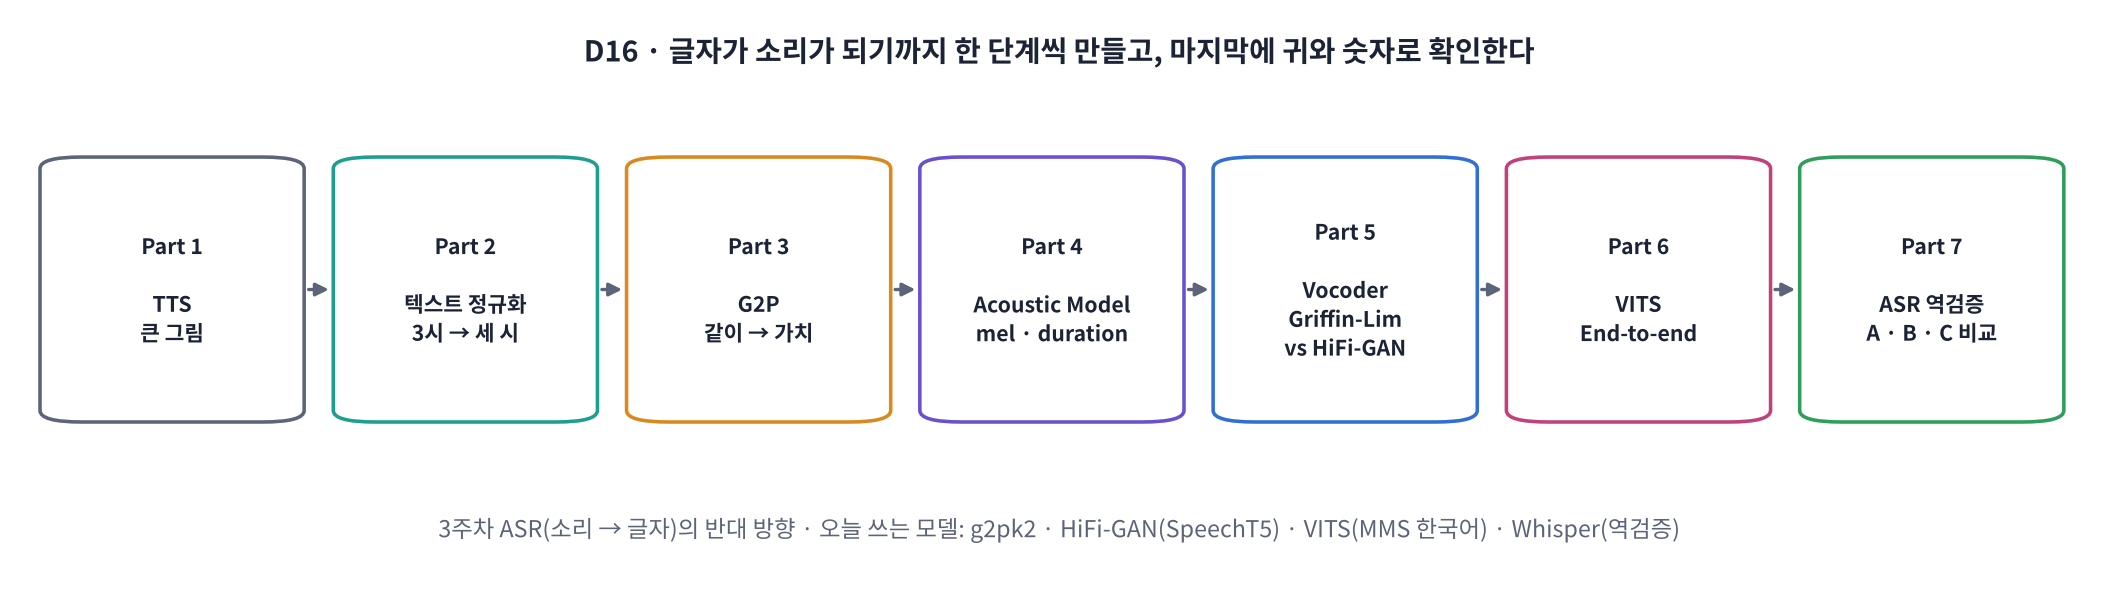

| 교시 | 내용 | 실습 |
|---|---|---|
| 1교시 | TTS 큰 그림, 한국어 텍스트 정규화 | Part 0 ~ 2, 워크시트 1교시 |
| 2교시 | 한글 자모 분해, 발음 규칙, G2P(g2pk2) | Part 3, 워크시트 2교시 |
| 3교시 | Acoustic Model(mel · duration), Vocoder(Griffin-Lim · HiFi-GAN) | Part 4 ~ 5, 워크시트 3교시 |
| 4교시 | End-to-end VITS, 정규화 · G2P 효과를 ASR 역검증으로 재기, 정리 | Part 6 ~ 8, 워크시트 4교시 · 노션 제출 |

## 오늘의 수업 자료
| 자료 | 링크 | 언제 쓰나요 |
|---|---|---|
| 🎬 인터랙티브 애니메이션 | [animation.html](https://imguru-mooc.github.io/AI_Voice/day16/animation.html) | 각 Part 설명을 볼 때 (Part마다 바로가기 링크가 있습니다) |
| 📝 개념 워크시트 | [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day16/worksheet.html) | 각 교시 끝에 해당 탭 10문항 (4교시 × 10문항), 오답 캡처 → 노션 |

## 이 노트북 사용법
- ▶️ 일반 코드 셀은 위에서부터 차례로 실행합니다. `!`로 시작하는 줄은 리눅스 명령입니다.
- 🧩 **빈칸 실습** 셀은 `____`(밑줄 4개)를 지우고 알맞은 값을 채운 뒤 실행합니다. 마지막 줄에서 ✅ 또는 ❌로 결과를 알려줍니다. 🔑 **정답 및 해설 보기**를 클릭하면 정답이 펼쳐집니다.
- 🎧 표시가 있는 셀은 **소리를 들어 보는** 셀입니다. 이어폰을 준비하세요.

| 표시 | 뜻 |
|---|---|
| 💬 **쉽게 말하면** | 그 절의 내용을 한 문장으로 |
| 🍎 **비유** | 일상의 장면으로 바꿔 보기 |
| 👣 **한 단계씩** | 무슨 일이 어떤 순서로 일어나는지 |
| 📐 **핵심 식 하나** | 꼭 기억할 식 하나 |
| ❓ **생각해 보기** | 스스로 답해 보고 펼쳐서 확인 |
| 🎧 **들어 보기** | 합성 결과를 귀로 비교 |

> ⚙️ **T4 GPU** 런타임을 권장합니다(4교시 ASR 역검증). Part 0 ~ 6은 CPU로도 돌아갑니다.
>
> 📜 **라이선스**: 오늘 쓰는 한국어 VITS(`facebook/mms-tts-kor`)는 **CC BY-NC 4.0(비상업)** 입니다. 수업 · 연구에는 쓸 수 있지만 **상업 서비스에는 쓸 수 없습니다.** HiFi-GAN(`microsoft/speecht5_hifigan`)은 MIT입니다.

> 🎬 **애니메이션 D16-1:** [오늘의 흐름](https://imguru-mooc.github.io/AI_Voice/day16/animation.html#flow) — Part 1~7 로드맵

> ## 🎤 강사 스크립트 · 도입  ⏱️ 7분
>
> 🎯 **4주차는 반대 방향. 오늘은 TTS를 부품 단위로 뜯어 본다.**
>
> 🗣️ "지난주에는 소리를 글자로 바꿨습니다. 이번 주에는 글자를 소리로 바꿉니다. 오늘은 TTS 모델을 **부품 하나씩** 열어 보고, 마지막에 '앞 처리 몇 줄이 결과를 얼마나 바꾸나'를 숫자로 확인합니다."
>
> 🎧 시작 질문(강사 화면에서 미리 만든 소리 두 개): Part 7의 '가격은 12,500원입니다' **A 원문**과 **C 정규화 + G2P** 소리를 들려주고 "무엇이 다른가요?" → 숫자를 빼먹음. "오늘 이 차이를 만드는 법을 배웁니다."
>
> 🖥️ [D16-1 오늘의 흐름](https://imguru-mooc.github.io/AI_Voice/day16/animation.html#flow)
>
> ➡️ "먼저 설치부터."

## Part 0. 준비

> 🛠️ **버전 충돌 방지 (D8 ~ D15와 같은 방식)**: Colab 기본 패키지 버전을 고정한 채 필요한 것만 설치합니다. 오늘 새로 쓰는 것은 **g2pk2**(한국어 G2P), **python-mecab-ko**(g2pk2가 쓰는 형태소 분석기, 미리 설치해 두면 g2pk2가 몰래 설치하지 않음), **uroman**(로마자 변환)입니다. TTS 모델은 `transformers` 안의 `VitsModel` · `SpeechT5HifiGan`을 써서 따로 설치하지 않습니다.

> ## 🎤 강사 스크립트 · Part 0  ⏱️ 5분
>
> 🖥️ 설치 셀 실행. g2pk2는 python-mecab-ko가 없으면 **스스로 pip install을 실행**하는 코드가 들어 있어, 그걸 막으려고 미리 설치한다는 점을 짚어 주세요(D8부터의 '버전 고정' 원칙).
>
> ✅ 출력: 버전 줄 + `GPU: Tesla T4`.

In [ ]:
# 📦 설치: Colab 기본 패키지 버전은 그대로 고정하고 필요한 것만 추가 (런타임 재시작 불필요)
import importlib.metadata as md
KEEP = ["torch", "torchaudio", "torchvision", "transformers", "tokenizers", "huggingface-hub",
        "datasets", "accelerate", "click", "numpy", "protobuf", "requests", "nltk", "regex"]
pins = []
for p in KEEP:
    try:
        pins.append(f"{p}=={md.version(p)}")
    except md.PackageNotFoundError:
        pass
open("colab_constraints.txt", "w").write("\n".join(pins) + "\n")
print("고정한 버전:", ", ".join(pins))

!pip install -q -c colab_constraints.txt python-mecab-ko g2pk2 jamo uroman jiwer soundfile librosa datasets
print("✅ 설치 완료")

In [ ]:
import os, io, re, time, math, json, random
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import torch
import jiwer
import matplotlib.pyplot as plt
from IPython.display import Audio, display
import importlib.metadata as md

SR = 16000
random.seed(0); np.random.seed(0); torch.manual_seed(0)

def check(cond, hint="빈칸을 다시 확인하세요."):
    print("✅ 정답입니다! 🎉" if cond else f"❌ {hint}")

GPU = torch.cuda.is_available()
DEVICE = "cuda" if GPU else "cpu"
print(" · ".join(f"{p} {md.version(p)}" for p in ["torch", "transformers", "g2pk2", "uroman", "librosa"]))
print("GPU:", torch.cuda.get_device_name(0) if GPU else "없음 (CPU로도 Part 0 ~ 6 가능)")

def play(y, sr=SR, label=""):                           # 🎧 짧게 듣기 + 길이 표시
    print(f"🎧 {label}  ({len(y) / sr:.2f}초)")
    display(Audio(np.asarray(y, dtype=np.float32), rate=sr))

## Part 1. TTS 큰 그림: 글자 → 발음 → 소리 그림 → 소리

> 💬 **쉽게 말하면**: ASR(받아쓰기)의 **반대 방향**입니다. 글자를 그대로 소리로 바꿀 수는 없어서, ① 읽는 대로 글자를 고치고(**정규화**) ② 발음 기호로 바꾸고(**G2P**) ③ 소리의 그림(**mel-spectrogram**)을 그리고(**Acoustic Model**) ④ 그림을 진짜 소리로 바꿉니다(**Vocoder**). 요즘 모델(VITS)은 ③ · ④를 한 모델에서 한 번에 합니다.

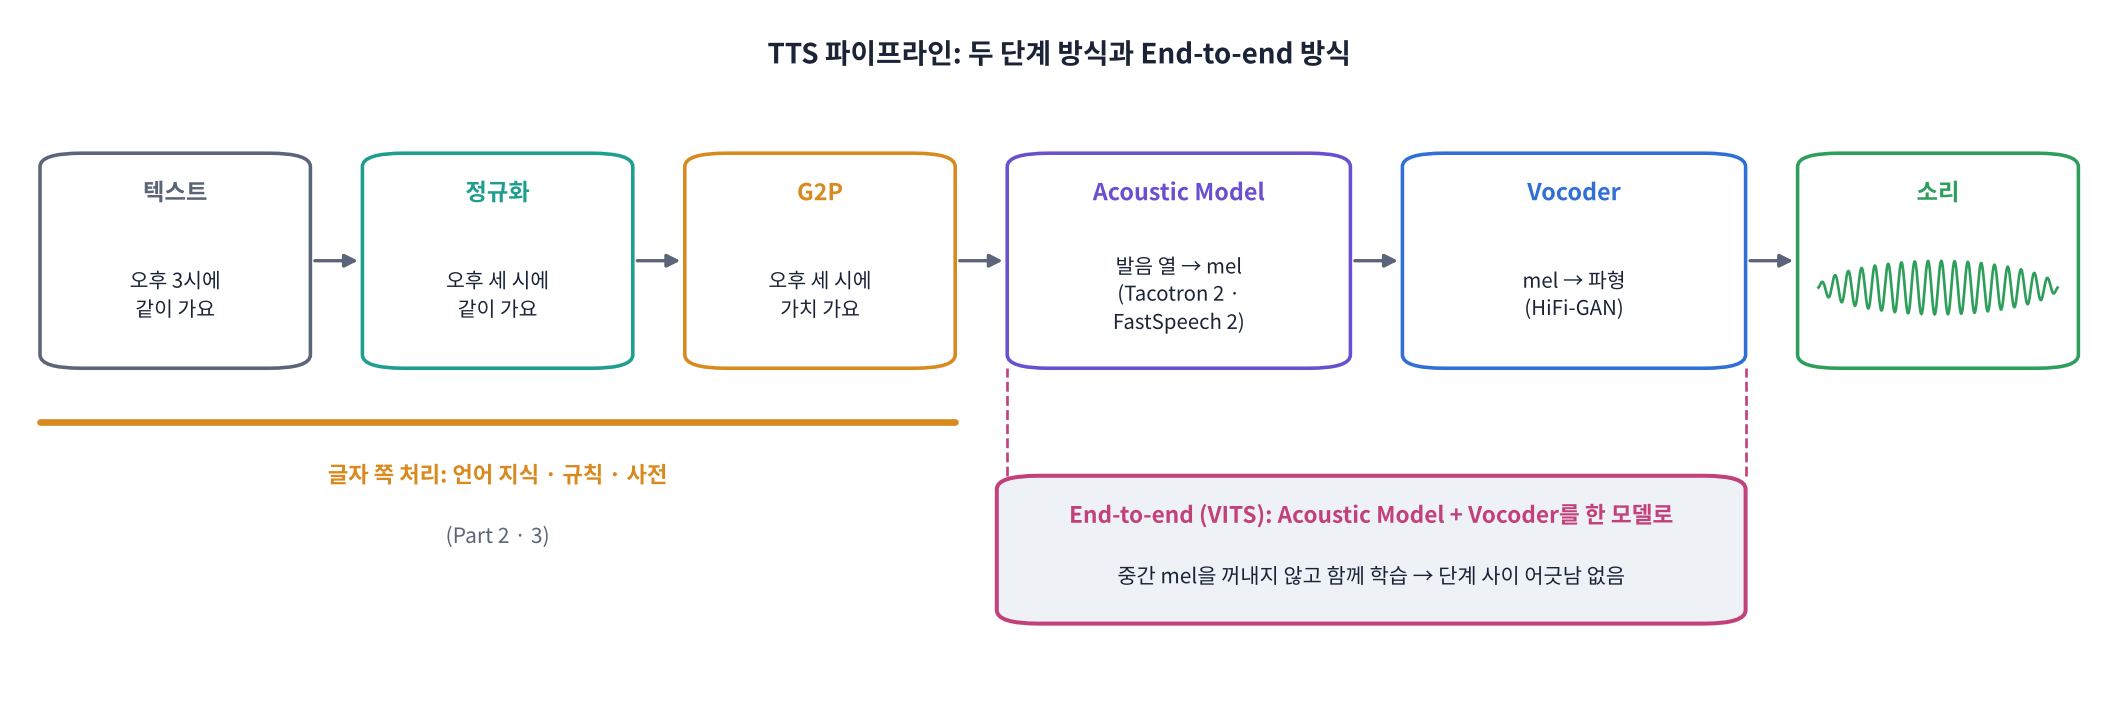

> 🍎 **비유: 악보를 연주하기까지.** 가사(텍스트)를 **읽기 쉬운 가사**로 다듬고(정규화: "3시" → "세 시"), **발음 표기**를 붙이고(G2P: "같이" → "가치"), 작곡가가 **악보**를 쓰고(Acoustic Model → mel), 연주자가 **악보를 소리로** 연주합니다(Vocoder). VITS는 작곡가와 연주자가 한 사람인 셈입니다.

| 단계 | 입력 → 출력 | 대표 방법 | 오늘 실습 |
|---|---|---|---|
| 텍스트 정규화 | "3시 15분" → "세 시 십오 분" | 규칙 · 사전, 최근엔 LLM | Part 2 (직접 만들기) |
| G2P | "같이" → "가치" | 발음 규칙 + 형태소 분석 | Part 3 (g2pk2) |
| Acoustic Model | 발음 열 → mel | Tacotron 2, FastSpeech 2 | Part 4 (mel · duration) |
| Vocoder | mel → 파형 | Griffin-Lim, WaveNet, **HiFi-GAN** | Part 5 |
| End-to-end | 발음 열 → 파형 | **VITS**, (D17) Kokoro, (D18) F5-TTS | Part 6 |

> 🎬 **애니메이션 D16-1:** [오늘의 흐름](https://imguru-mooc.github.io/AI_Voice/day16/animation.html#flow) — 단계를 눌러 입력 · 출력 예 보기

> ## 🎤 강사 스크립트 · Part 1 큰 그림  ⏱️ 10분
>
> 🎯 **정규화 → G2P → Acoustic Model → Vocoder, 그리고 VITS는 뒤 두 개를 한 몸으로.**
>
> 🍎 "악보를 연주하기까지" 비유로 그림을 짚어 가며 설명.
>
> ❓ "ASR은 정답이 하나인데 TTS는?" → 일대다. 같은 문장을 여러 학생에게 읽게 해 보세요(빠르기 · 억양이 다 다름). → duration · noise가 필요한 이유, 평가가 어려운 이유(D20).

**❓ 생각해 보기**: ASR은 '소리 → 글자' 한 가지 정답(받아쓴 글자)이 있는데, TTS는 '글자 → 소리'의 정답이 하나일까요?

<details>
<summary>답 보기</summary>

**아닙니다.** 같은 문장도 빠르기 · 높낮이 · 감정 · 목소리에 따라 수없이 많은 '맞는' 소리가 있습니다(일대다, one-to-many). 그래서 TTS는 ① 길이(duration)를 따로 예측하거나 ② 무작위성(noise)을 넣어 여러 가능성 중 하나를 고르고 ③ 평가도 '정답과 똑같은가'가 아니라 **사람이 듣기에 자연스러운가(MOS)** · **알아듣게 말했나(ASR 역검증 CER)** 로 합니다(D20).

</details>

## Part 2. 텍스트 정규화: 읽는 대로 글자를 고치기

> 💬 **쉽게 말하면**: TTS 모델은 **'3'이나 '%'를 어떻게 읽는지 모릅니다.** 오늘 쓰는 한국어 VITS는 숫자를 아예 **지워 버립니다**(Part 6에서 확인). 그래서 숫자 · 단위 · 기호 · 영문 약어를 **사람이 읽는 말**로 먼저 바꿉니다.

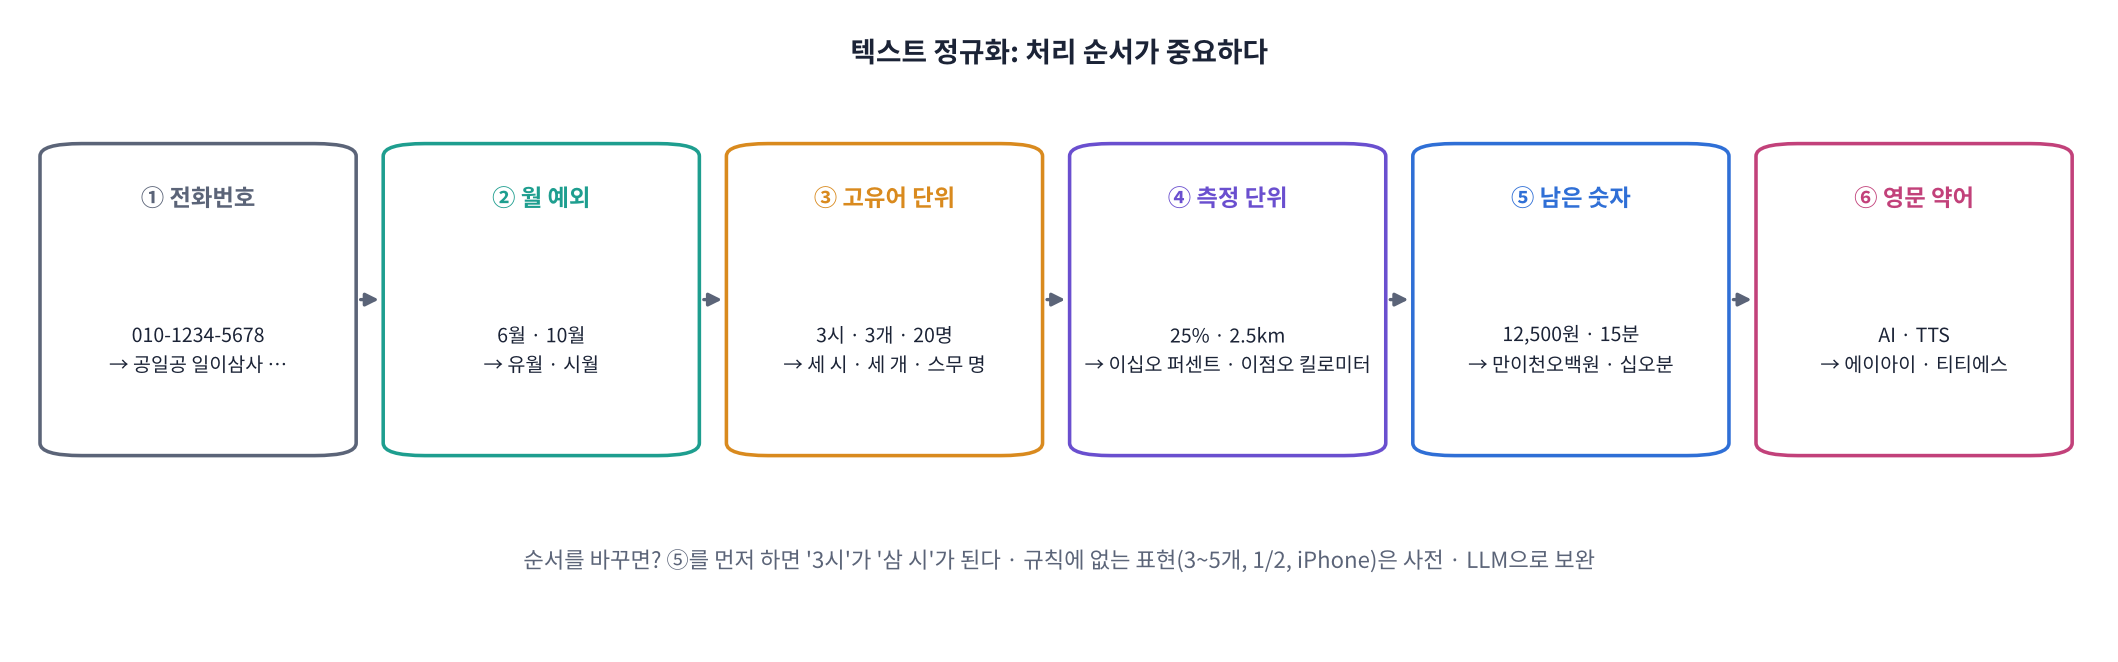

한국어 숫자는 **두 가지 읽기**가 있어 특히 까다롭습니다.

| 읽기 | 예 | 언제 |
|---|---|---|
| 한자어 수 (일, 이, 삼 …) | 2026년, 10월, 15분, 12,500원, 25% | 날짜 · 분 · 돈 · 단위 · 번호 |
| 고유어 수 (한, 두, 세 …) | 3시, 3개, 2병, 20명(스무 명) | 시(時) · 개수 단위(개 · 명 · 살 · 병 · 마리 …) |
| 예외 | 6월 → 유월, 10월 → 시월, 010 → 공일공 | 사전으로 처리 |

> 📐 **핵심 식 하나: 한자어 수 = (자릿수 숫자 + 단위)를 네 자리씩(만 · 억 · 조) 묶어 읽기** — 12,500 = 1만 + 2천 + 5백 → "만이천오백" (앞자리 1은 '일'을 빼고 읽음: 십 · 백 · 천 · 만)

> 🎬 **애니메이션 D16-2:** [정규화 실험실](https://imguru-mooc.github.io/AI_Voice/day16/animation.html#norm) — 문장을 직접 입력해 단계별로 어떻게 바뀌는지 보기

> ## 🎤 강사 스크립트 · Part 2 정규화  ⏱️ 8분
>
> 🎯 **모델은 숫자를 읽을 줄 모른다. 읽는 대로 바꿔 주는 것이 첫 단계.**
>
> 🖥️ [D16-2 정규화 실험실](https://imguru-mooc.github.io/AI_Voice/day16/animation.html#norm): "회의는 오후 3시 15분에" 입력 → 단계별 변화. '순서 바꾸기'를 켜면 '삼 시'가 되는 것.
>
> ❓ 반 전체 퀴즈: "3시 15분", "3개", "20명", "6월", "010" 읽어 보기 → 세 시 십오 분, 세 개, 스무 명, 유월, 공일공.

### 🧩 빈칸 실습 1 · 2: 숫자 읽기 함수
- 빈칸 1: 자릿수 숫자를 한글로 읽는 문자열(`"영일이삼사오육칠팔구"`)을 담은 **변수 이름**. 단, 십 · 백 · 천 자리의 1은 읽지 않습니다("일십" ✗ → "십").
- 빈칸 2: 숫자 뒤의 단위가 **고유어 수를 쓰는 단위 목록**에 있는지 확인합니다. 그 목록 변수 이름을 넣으세요.

In [ ]:
# 🧩 빈칸 실습 1 · 2
DIGITS = "영일이삼사오육칠팔구"

def sino(n):                                            # 한자어 수: 12500 → 만이천오백
    if n == 0:
        return "영"
    out = ""
    for big in ["", "만", "억", "조"]:                  # 네 자리씩 끊어 읽기
        chunk, n = n % 10000, n // 10000
        s = ""
        for i, unit in enumerate(["", "십", "백", "천"]):
            d, chunk = chunk % 10, chunk // 10
            if d:
                s = ("" if d == 1 and i > 0 else ____[d]) + unit + s                   # 빈칸 1
        if s:
            out = ("" if s == "일" and big == "만" else s) + big + out
        if n == 0:
            break
    return out

ONES = ["", "한", "두", "세", "네", "다섯", "여섯", "일곱", "여덟", "아홉"]   # 단위 앞 고유어 (관형사형)
TENS = ["", "열", "스물", "서른", "마흔", "쉰", "예순", "일흔", "여든", "아흔"]
def native(n):                                          # 고유어 수: 3 → 세, 20 → 스무, 21 → 스물한
    if not 0 < n < 100:
        return sino(n)                                  # 100 이상은 보통 한자어로 읽음
    return "스무" if n == 20 else TENS[n // 10] + ONES[n % 10]

NATIVE_COUNTERS = ["시간", "개", "명", "살", "마리", "권", "잔", "병", "장", "달", "시"]   # '시간'을 '시'보다 먼저

def read_count(n, unit):
    return (native(n) if unit in ____ else sino(n)) + " " + unit                          # 빈칸 2

print([sino(n) for n in [15, 101, 2026, 12500, 100000000]])
print([read_count(n, u) for n, u in [(3, "시"), (15, "분"), (20, "명"), (3, "개"), (25, "층")]])
check(sino(12500) == "만이천오백" and sino(2026) == "이천이십육" and read_count(3, "시") == "세 시"
      and read_count(15, "분") == "십오 분" and read_count(20, "명") == "스무 명", hint="빈칸 1 = DIGITS, 빈칸 2 = NATIVE_COUNTERS")

> ## 🎤 강사 스크립트 · 빈칸 실습 1 · 2  ⏱️ 10분
>
> 🆘 빈칸 1: "숫자 d를 한글로 읽은 글자는 어떤 문자열의 d번째?" → `DIGITS`
> 🆘 빈칸 2: "고유어로 읽는 단위 목록 이름" → `NATIVE_COUNTERS`
>
> ✅ 예상 출력: `['십오', '백일', '이천이십육', '만이천오백', '일억']`, `['세 시', '십오 분', '스무 명', '세 개', '이십오 층']`, `✅`. 이어서 정규화 표 12줄.
>
> ⚠️ '1억'이 '일억'인데 '1만'은 '만' — 한국어 관습. 학생이 물으면 "만은 일을 빼고, 억 · 조는 붙여 읽는 경우가 많다"고.
>
> ❓ 표를 보며: "규칙이 틀린 줄은?" → 대부분 맞음. ❓ 생각해 보기의 '3~5개' 등은 과제 1.

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
s = ("" if d == 1 and i > 0 else DIGITS[d]) + unit + s
return (native(n) if unit in NATIVE_COUNTERS else sino(n)) + " " + unit
```

**해설**: `sino()`는 네 자리씩 끊어(만 · 억 · 조) 각 덩어리를 '천 · 백 · 십 · 일' 자리로 읽습니다. 십 · 백 · 천 자리의 1은 생략하고(십오, 백일), 10000은 '일만'이 아니라 '만'으로 읽습니다. 고유어 수는 단위 앞에서 모양이 바뀝니다(하나 → **한**, 둘 → **두**, 셋 → **세**, 넷 → **네**, 스물 → **스무**). '층 · 분 · 원 · 년'은 한자어, '시 · 개 · 명 · 살'은 고유어입니다. 목록에 없는 단위는 한자어로 읽으므로, 서비스 분야에 맞춰 목록을 늘려 가는 것이 실무 방식입니다.

</details>

### 2-1. 문장 전체 정규화기
전화번호 → 월(유월 · 시월) → 고유어 단위 → 측정 단위 · % → 남은 숫자 → 영문 약어 순서로 바꿉니다. **순서가 중요합니다.** 예를 들어 남은 숫자를 먼저 바꾸면 "3시"가 "삼 시"가 되어 버립니다.

In [ ]:
UNITS = {"km": "킬로미터", "kg": "킬로그램", "cm": "센티미터", "mm": "밀리미터", "%": "퍼센트", "℃": "도",
         "GB": "기가바이트", "MB": "메가바이트"}
LETTERS = dict(zip("ABCDEFGHIJKLMNOPQRSTUVWXYZ", ["에이", "비", "씨", "디", "이", "에프", "지", "에이치", "아이", "제이", "케이", "엘", "엠",
                                                  "엔", "오", "피", "큐", "알", "에스", "티", "유", "브이", "더블유", "엑스", "와이", "지"]))
MONTH = {6: "유월", 10: "시월"}

def read_number(s):                                     # "12,500" · "2.5" 같은 숫자 문자열
    s = s.replace(",", "")
    if "." in s:
        a, b = s.split(".", 1)
        return sino(int(a)) + "점" + "".join(DIGITS[int(c)] for c in b)
    return sino(int(s))

def normalize_ko(text):
    t = text
    t = re.sub(r"(\d{2,3})-(\d{3,4})-(\d{4})",            # 전화번호: 한 자리씩, 0은 '공'
               lambda m: " ".join("".join("공" if c == "0" else DIGITS[int(c)] for c in g) for g in m.groups()), t)
    t = re.sub(r"(\d+)\s*월", lambda m: MONTH.get(int(m.group(1)), sino(int(m.group(1))) + "월"), t)
    t = re.sub(r"(\d+)\s*(" + "|".join(NATIVE_COUNTERS) + ")", lambda m: read_count(int(m.group(1)), m.group(2)), t)
    t = re.sub(r"(\d[\d,]*(?:\.\d+)?)\s*(" + "|".join(map(re.escape, UNITS)) + ")",
               lambda m: read_number(m.group(1)) + " " + UNITS[m.group(2)], t)
    t = re.sub(r"\d[\d,]*(?:\.\d+)?", lambda m: read_number(m.group(0)), t)
    t = re.sub(r"(?<![A-Za-z])[A-Z]{2,}(?![A-Za-z])", lambda m: "".join(LETTERS[c] for c in m.group(0)), t)
    return re.sub(r"\s+", " ", t).strip()

TEST_SENTS = [
    "오늘은 2026년 10월 23일입니다", "회의는 오후 3시 15분에 시작합니다", "사과 3개와 우유 2병을 샀어요",
    "할인율은 25%입니다", "가격은 12,500원입니다", "문의는 010-1234-5678로 전화 주세요",
    "AI 음성 합성 기술이 빠르게 발전하고 있습니다", "학교까지 2.5km 걸어갔습니다",
    "같이 밥을 먹으러 갈까요", "국물이 정말 맛있네요", "설날에 떡국을 먹었어요", "닭고기를 볶아서 먹었다",
]
display(pd.DataFrame({"원문": TEST_SENTS, "정규화": [normalize_ko(s) for s in TEST_SENTS]}))

**❓ 생각해 보기**: '3~5개', '1/2', '제3장', '2:1로 이겼다', 'iPhone 17'은 위 정규화기로 어떻게 될까요? 어떻게 고치면 될까요?

<details>
<summary>답 보기</summary>

모두 아직 틀립니다. '3~5개'는 '삼~다섯 개'처럼 섞이고(→ '세에서 다섯 개' 규칙), '1/2'은 '일/이'(→ '이분의 일'), '제3장'은 '제삼장'으로 맞지만 '3장'(종이)은 '세 장', '2:1'은 '이:일'(→ '이 대 일'), 'iPhone'은 소문자가 섞여 그대로 남습니다(→ 외래어 사전). 규칙은 끝이 없어서 실무에서는 ① 분야별 규칙 · 사전을 계속 늘리거나 ② **LLM에게 '읽는 대로 써 줘'** 를 맡기고 규칙으로 검사하는 방법을 함께 씁니다(5주차). 어떤 방법이든 **정규화 전후를 표로 남겨 검토**하는 습관이 중요합니다.

</details>

---
### 📝 1교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 1교시 탭](https://imguru-mooc.github.io/AI_Voice/day16/worksheet.html)** — TTS 4단계, ASR과의 차이(일대다), 정규화가 필요한 이유, 한자어 수 · 고유어 수, 관형사형(한 · 두 · 세 · 스무), 예외(유월 · 시월 · 공), 처리 순서
>
> 10문항을 풀고 **채점하기**를 누르세요. 채점 후에는 답이 잠깁니다. 제출은 4교시까지 모두 마친 뒤 한 번에 합니다.

> ## 🎤 강사 스크립트 · 1교시 워크시트  ⏱️ 5분
>
> 🖥️ [worksheet.html 1교시 탭](https://imguru-mooc.github.io/AI_Voice/day16/worksheet.html) → 채점.
>
> 자주 틀리는 문항: **고유어 단위 고르기(분 · 층은 한자어)**, **처리 순서**.

## Part 3. G2P: 쓰는 대로가 아니라 소리 나는 대로

> 💬 **쉽게 말하면**: 한국어는 **쓴 글자와 소리가 다릅니다.** '같이'는 [가치], '국물'은 [궁물], '학교'는 [학꾜]로 소리 납니다. G2P(Grapheme-to-Phoneme)는 글자를 **발음 열**로 바꾸는 단계입니다. 먼저 한글 음절을 **자모(초성 · 중성 · 종성)** 로 나누는 법부터 봅니다.

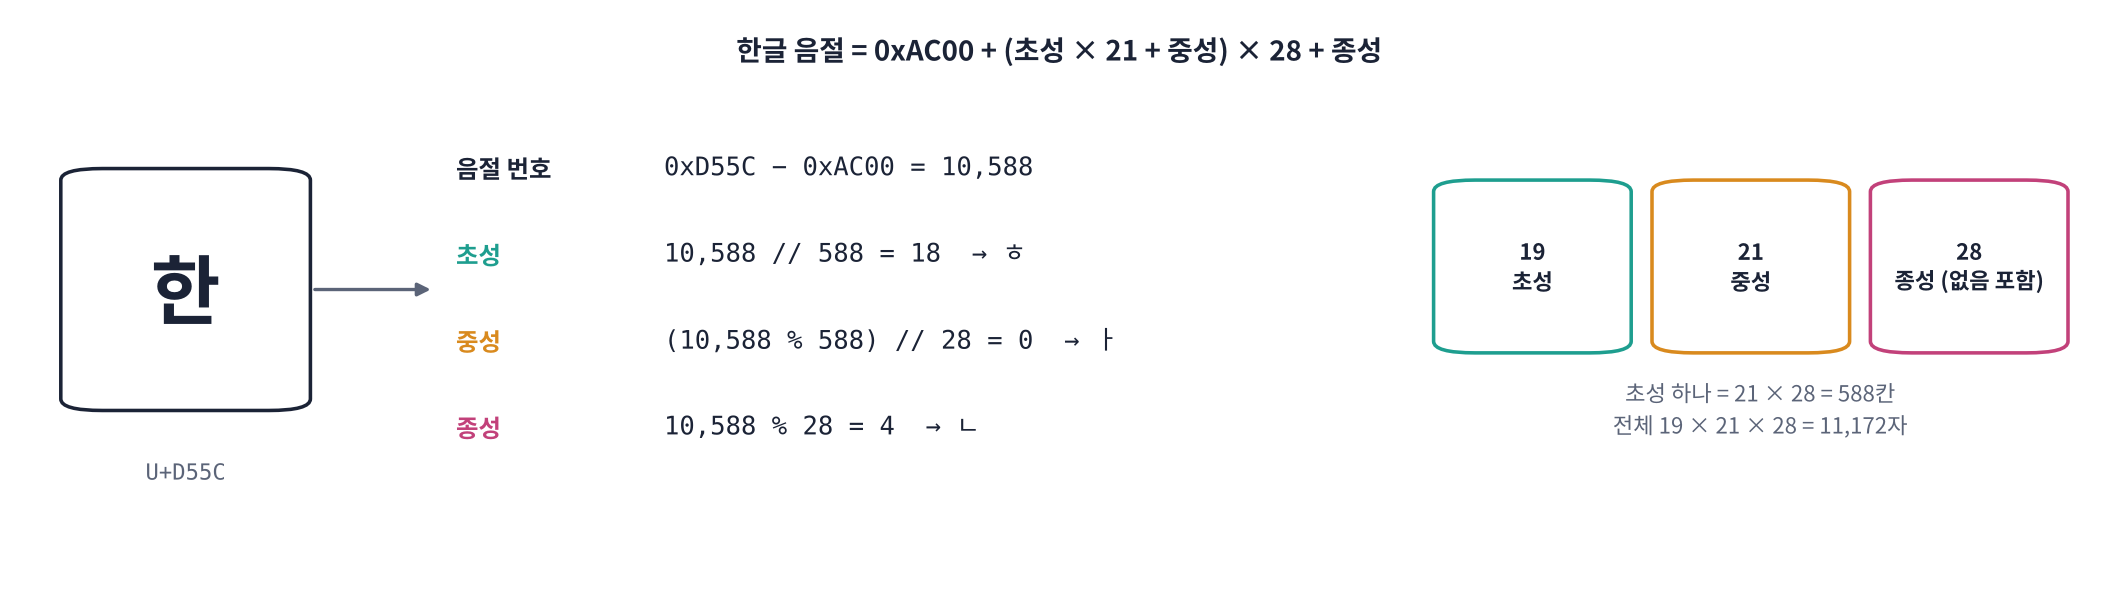

> 📐 **핵심 식 하나: 음절 코드 = 0xAC00 + (초성 × 21 + 중성) × 28 + 종성** — 초성 19개 · 중성 21개 · 종성 28개(받침 없음 포함). 그래서 초성 하나가 21 × 28 = **588**칸을 차지합니다.

> 🎬 **애니메이션 D16-3:** [한글 분해 계산기](https://imguru-mooc.github.io/AI_Voice/day16/animation.html#hangul) — 음절을 입력하면 초성 · 중성 · 종성 번호가 계산되는 과정

> ## 🎤 강사 스크립트 · Part 3 G2P  ⏱️ 10분
>
> 🎯 **한국어는 쓴 대로 소리 나지 않는다. 음절 = 초성 · 중성 · 종성 번호의 계산.**
>
> 🖥️ [D16-3 한글 분해 계산기](https://imguru-mooc.github.io/AI_Voice/day16/animation.html#hangul): 학생 이름 첫 글자를 넣어 보게 하기.
>
> 🗣️ "유니코드 표에서 한글 11,172자는 **규칙적으로** 놓여 있습니다. 초성이 하나 바뀌면 588칸 건너뜁니다."

### 🧩 빈칸 실습 3 · 4: 자모 분해와 연음 규칙
- 빈칸 3: 초성 번호 = 음절 번호 ÷ (초성 하나가 차지하는 칸 수). 위 핵심 식에서 계산한 **숫자**를 넣으세요.
- 빈칸 4: **연음**은 받침이 있는 음절 뒤에 **소리 없는 초성**으로 시작하는 음절이 오면, 받침이 뒤로 넘어가는 규칙입니다(밥을 → 바블). 그 초성 자모를 넣으세요.

In [ ]:
# 🧩 빈칸 실습 3 · 4
CHO  = list("ㄱㄲㄴㄷㄸㄹㅁㅂㅃㅅㅆㅇㅈㅉㅊㅋㅌㅍㅎ")                                   # 19
JUNG = list("ㅏㅐㅑㅒㅓㅔㅕㅖㅗㅘㅙㅚㅛㅜㅝㅞㅟㅠㅡㅢㅣ")                             # 21
JONG = [""] + list("ㄱㄲㄳㄴㄵㄶㄷㄹㄺㄻㄼㄽㄾㄿㅀㅁㅂㅄㅅㅆㅇㅈㅊㅋㅌㅍㅎ")               # 28 (받침 없음 포함)

def decompose(ch):
    code = ord(ch) - 0xAC00
    if not 0 <= code < 11172:
        return None                                     # 한글 음절이 아니면 그대로 둠
    return CHO[code // ____], JUNG[(code % 588) // 28], JONG[code % 28]                    # 빈칸 3

def compose(cho, jung, jong=""):
    return chr(0xAC00 + (CHO.index(cho) * 21 + JUNG.index(jung)) * 28 + JONG.index(jong))

SPLIT = {"ㄳ": ("ㄱ", "ㅅ"), "ㄵ": ("ㄴ", "ㅈ"), "ㄺ": ("ㄹ", "ㄱ"), "ㄻ": ("ㄹ", "ㅁ"), "ㄼ": ("ㄹ", "ㅂ"), "ㄾ": ("ㄹ", "ㅌ"),
         "ㄿ": ("ㄹ", "ㅍ"), "ㅄ": ("ㅂ", "ㅅ")}                                            # 겹받침: 뒤 자음이 넘어감

def linking(word):                                      # 연음 규칙 하나만 적용 (한 어절 안에서)
    syl = [list(decompose(c)) if decompose(c) else c for c in word]
    for i in range(len(syl) - 1):
        a, b = syl[i], syl[i + 1]
        if isinstance(a, list) and isinstance(b, list) and a[2] and a[2] not in ("ㅇ", "ㅎ") and b[0] == ____:   # 빈칸 4
            keep, move = SPLIT.get(a[2], ("", a[2]))
            a[2], b[0] = keep, move
    return "".join(compose(*s) if isinstance(s, list) else s for s in syl)

print("한:", decompose("한"), " 값:", decompose("값"), " 닭:", decompose("닭"))
print([linking(w) for w in ["밥을", "음악", "국어", "닭이", "값이", "앉아", "좋아", "같이"]])
check(decompose("한") == ("ㅎ", "ㅏ", "ㄴ") and linking("밥을") == "바블" and linking("닭이") == "달기" and linking("값이") == "갑시",
      hint="빈칸 3 = 588, 빈칸 4 = \"ㅇ\"")

> ## 🎤 강사 스크립트 · 빈칸 실습 3 · 4  ⏱️ 12분
>
> 🆘 빈칸 3: "초성 하나 = 중성 21 × 종성 28" → `588`
> 🆘 빈칸 4: "'을' '이' '아'의 초성은? 소리가 없는 그 자음" → `"ㅇ"`
>
> ✅ 예상 출력: `한: ('ㅎ', 'ㅏ', 'ㄴ')  값: ('ㄱ', 'ㅏ', 'ㅄ')  닭: ('ㄷ', 'ㅏ', 'ㄺ')`, `['바블', '으막', '구거', '달기', '갑시', '안자', '좋아', '가티']`, `✅`.
>
> ❓ "'같이'가 '가티'로 나왔는데 맞나요?" → 아니요, [가치]. 구개음화. "'좋아'는?" → [조아], ㅎ 탈락. → 규칙이 많고 순서가 중요 → g2pk2.
>
> 🖥️ [D16-4 발음 규칙 탐색기](https://imguru-mooc.github.io/AI_Voice/day16/animation.html#g2p): 규칙을 하나씩 켜기.
>
> 다음 셀(g2pk2) 첫 실행은 10 ~ 30초. ✅ 출력: 단어 표 + 문장 표. '의사의 의견'이 descriptive에서 '의사에 의견'.

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
return CHO[code // 588], JUNG[(code % 588) // 28], JONG[code % 28]
... and b[0] == "ㅇ":
```

**해설**: '한'은 0xD55C − 0xAC00 = 10,588 → 초성 10588 ÷ 588 = 18(ㅎ), 중성 (10588 % 588) ÷ 28 = 0(ㅏ), 종성 10588 % 28 = 4(ㄴ). 연음은 뒤 음절 초성이 **소리 없는 ㅇ**일 때 받침이 넘어가는 규칙이고, 겹받침은 **뒤 자음만** 넘어갑니다(닭이 → 달기, 값이 → 갑시 → 실제 발음은 경음화까지 [갑씨]). ㅎ 받침은 넘어가지 않고 사라집니다(좋아 → [조아]). 마지막 '같이'는 연음만 하면 '가티'인데 실제 발음은 **[가치]**(구개음화)입니다. 규칙 하나로는 부족하다는 뜻이고, 그래서 규칙 수십 개를 순서대로 적용하는 g2pk2를 씁니다.

</details>

### 3-1. g2pk2: 규칙 수십 개 + 형태소 분석

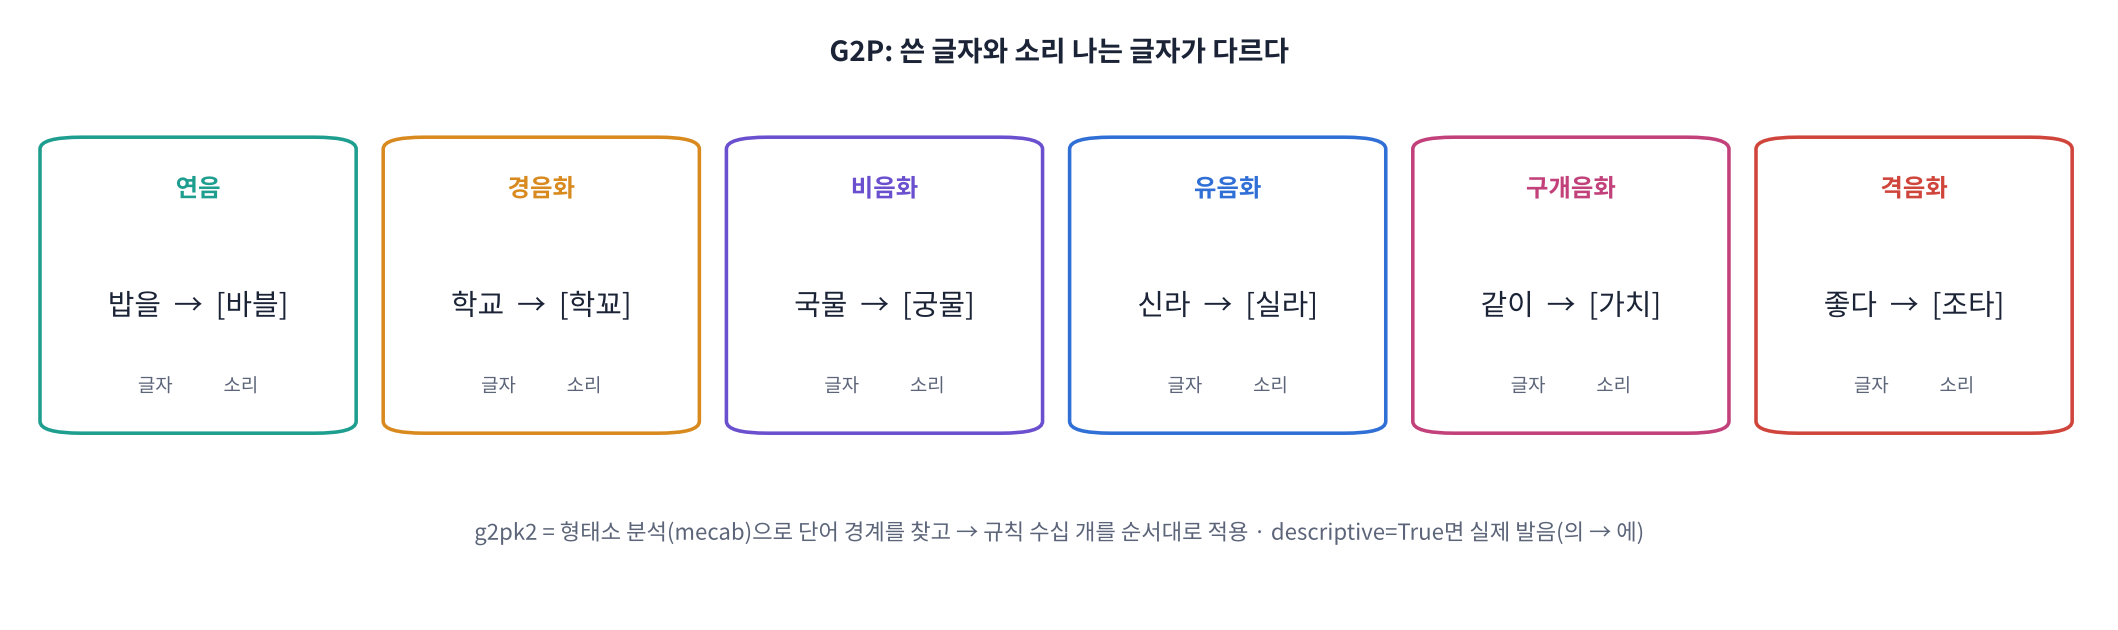

| 규칙 | 예 | 발음 |
|---|---|---|
| 연음 | 밥을, 음악 | [바블], [으막] |
| 경음화 | 학교, 국밥 | [학꾜], [국빱] |
| 비음화 | 국물, 합니다 | [궁물], [함니다] |
| 유음화 | 신라, 설날 | [실라], [설랄] |
| 구개음화 | 같이, 굳이 | [가치], [구지] |
| 격음화 · ㅎ 탈락 | 좋다, 좋아 | [조타], [조아] |
| 의 발음 (descriptive) | 의사의 의견 | [의사에 의견] |

g2pk2는 문장을 **형태소로 나눈 뒤**(mecab) 규칙을 적용합니다. 같은 글자라도 단어 경계에 따라 발음이 달라지기 때문입니다. `descriptive=True`면 표준 발음 대신 **실제 많이 쓰는 발음**(의 → 에)을 냅니다.

> 🎬 **애니메이션 D16-4:** [발음 규칙 탐색기](https://imguru-mooc.github.io/AI_Voice/day16/animation.html#g2p) — 규칙을 하나씩 켜며 단어가 어떻게 바뀌는지 보기

In [ ]:
from g2pk2 import G2p
g2p = G2p()                                             # 처음 한 번 사전 · 형태소 분석기 준비 (수 초)

words = ["밥을", "음악", "국어", "닭이", "값이", "앉아", "좋아", "같이", "국물", "학교", "신라", "합니다", "의사의 의견"]
rows = []
for w in words:
    rows.append({"글자": w, "연음만 (직접)": linking(w) if " " not in w else "—", "g2pk2": g2p(w), "g2pk2 descriptive": g2p(w, descriptive=True)})
display(pd.DataFrame(rows))

G2P_TABLE = pd.DataFrame({"원문": TEST_SENTS})
G2P_TABLE["g2p(원문)"] = [g2p(s) for s in TEST_SENTS]
G2P_TABLE["g2p(정규화)"] = [g2p(normalize_ko(s)) for s in TEST_SENTS]
display(G2P_TABLE)

**결과 읽기**
- g2pk2도 숫자를 일부 읽어 줍니다(3시 → [세시], 12,500원 → [마니처노배궈]). 하지만 **틀리는 곳**도 있습니다: '우유 2병' → [이병](→ 두 병), '010-1234' → [영이령-이리삼사](→ 공일공), '2.5km' → [이.오km](단위를 못 읽음). 두 열을 비교해 보세요. 정규화기를 먼저 거친 쪽이 더 정확합니다.
- 'AI'는 g2pk2가 영어 발음 사전(CMUdict)으로 **[아이]** 로 읽습니다. 우리 정규화기는 **[에이아이]**. 어느 쪽이 맞는지는 **서비스의 약속**(용어 사전)으로 정합니다.

**❓ 생각해 보기**: G2P 결과 '바블'을 그대로 TTS에 넣으면, 모델이 '바블'이라는 단어를 알고 있어야 할까요?

<details>
<summary>답 보기</summary>

아닙니다. TTS 모델 입력은 **단어가 아니라 기호(글자 · 자모 · 음소)의 열**입니다. '바블'은 'ㅂ ㅏ ㅂ ㅡ ㄹ'(또는 로마자 b a b e u l)이라는 소리 기호 열일 뿐이라, 처음 보는 단어도 읽을 수 있습니다. 대신 **글자와 소리가 다른 곳**(연음 · 경음화 …)은 모델이 데이터에서 스스로 배워야 하는데, G2P를 거치면 그 부담을 덜어 줍니다. 데이터가 적은 한국어 모델일수록 G2P 효과가 큽니다(Part 7에서 확인).

</details>

---
### 📝 2교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 2교시 탭](https://imguru-mooc.github.io/AI_Voice/day16/worksheet.html)** — G2P가 필요한 이유, 초성 · 중성 · 종성 개수, 588 · 28 계산, 연음 · 겹받침, 경음화 · 비음화 · 유음화 · 구개음화 · 격음화, 형태소 분석, descriptive
>
> 10문항을 풀고 **채점하기**를 누르세요.

> ## 🎤 강사 스크립트 · 2교시 워크시트  ⏱️ 5분
>
> 🖥️ [worksheet.html 2교시 탭](https://imguru-mooc.github.io/AI_Voice/day16/worksheet.html). 자주 틀리는 문항: **588 계산**, **겹받침 연음(닭이 → 달기)**, **구개음화 예**.

## Part 4. Acoustic Model: 발음 열 → 소리 그림(mel)

> 💬 **쉽게 말하면**: Acoustic Model은 발음 열을 받아 **mel-spectrogram**(D3에서 본 '소리의 그림')을 그립니다. 핵심 문제는 **길이**입니다. 글자는 10개인데 mel은 수백 프레임이라, 발음 기호 하나를 **몇 프레임 동안 낼지(duration)** 를 정해야 합니다.

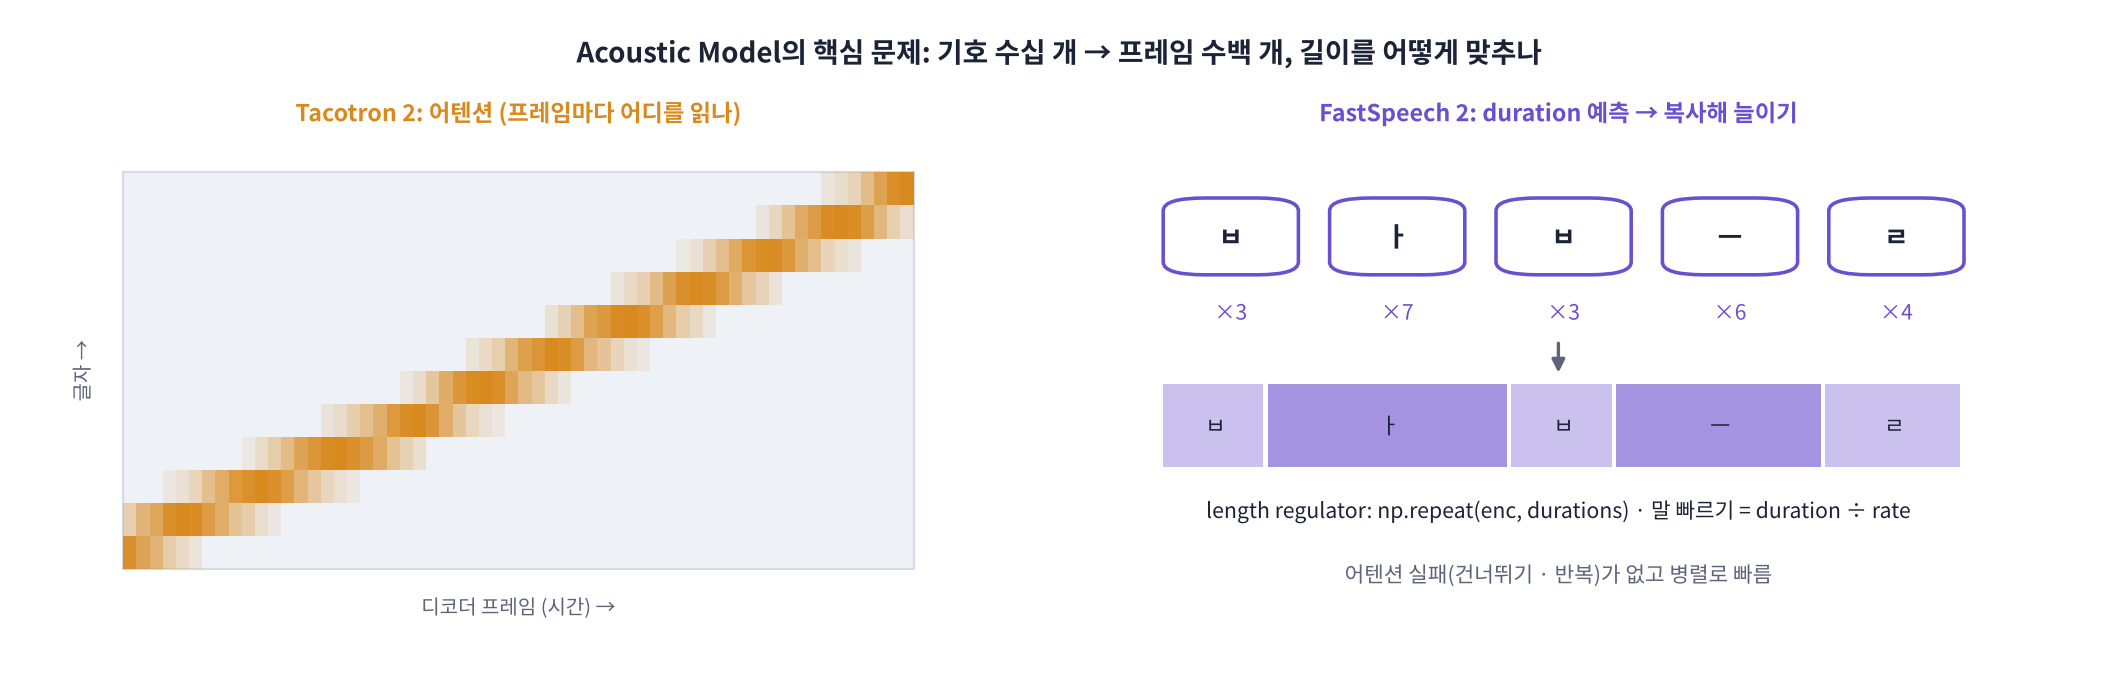

| 모델 | 길이를 정하는 방법 | 특징 |
|---|---|---|
| Tacotron 2 (2017) | **어텐션**이 프레임마다 '지금 어느 글자를 읽나'를 찾음 | 자연스럽지만 느리고, 가끔 건너뛰거나 반복(어텐션 실패) |
| FastSpeech 2 (2020) | **Duration predictor**가 글자마다 프레임 수를 예측 → 그만큼 복사 | 빠르고(병렬) 안정적, 속도 조절 쉬움 |
| VITS (2021) | Duration predictor + 학습 때 정렬을 스스로 찾음(MAS) | Part 6 |

> 📐 **핵심 식 하나: 프레임 수 ≈ 소리 길이(샘플) ÷ hop** — 16 kHz · hop 256이면 1초 = 62.5 프레임, 한 프레임 = 16 ms.

> 🎬 **애니메이션 D16-5:** [mel 만들기](https://imguru-mooc.github.io/AI_Voice/day16/animation.html#mel) — n_fft · hop · n_mels를 바꾸며 그림이 어떻게 바뀌는지

> ## 🎤 강사 스크립트 · Part 4 Acoustic Model  ⏱️ 8분
>
> 🎯 **기호 수십 개 → 프레임 수백 개. 길이(duration)를 정하는 것이 핵심.**
>
> 🖥️ [D16-5 mel 만들기](https://imguru-mooc.github.io/AI_Voice/day16/animation.html#mel): hop을 바꾸면 프레임 수가 바뀌는 것.
>
> 🗣️ "Tacotron 2는 프레임마다 '지금 어느 글자?'를 어텐션으로 찾습니다. 가끔 길을 잃어 같은 말을 반복하거나 건너뜁니다. FastSpeech는 처음부터 '이 글자는 7프레임'이라고 정해 버립니다."

In [ ]:
from datasets import load_dataset, Audio as HFAudio

def read_audio(ex):
    y, sr = sf.read(io.BytesIO(ex["audio"]["bytes"]), dtype="float32")
    if y.ndim > 1:
        y = y.mean(axis=1)
    return (librosa.resample(y, orig_sr=sr, target_sr=SR) if sr != SR else y).astype(np.float32)

zt = load_dataset("kresnik/zeroth_korean", split="test", streaming=True).cast_column("audio", HFAudio(decode=False))
best = None
for k, ex in enumerate(zt):                             # 5초 안팎의 실제 사람 녹음 하나 (3~7초면 바로 사용)
    y = read_audio(ex)
    if best is None or abs(len(y) / SR - 5) < abs(len(best[0]) / SR - 5):
        best = (y, ex["text"])
    if 3 <= len(y) / SR <= 7 or k >= 50:
        break
y_real, REAL_TEXT = best
y_real = y_real / (np.abs(y_real).max() + 1e-9) * 0.9
print("문장:", REAL_TEXT)
play(y_real, label="원본 (Zeroth 사람 녹음)")

### 🧩 빈칸 실습 5: mel 프레임 수
오늘 mel 설정은 HiFi-GAN과 같게 맞춥니다: `n_fft = 1024`(64 ms 창), `hop = 256`(16 ms 간격), `n_mels = 80`. `librosa`는 소리 앞뒤를 반 창씩 덧대므로(center) **프레임 수 = 1 + 샘플 수 ÷ hop**(몫)입니다. 알맞은 변수를 넣으세요.

In [ ]:
# 🧩 빈칸 실습 5
N_FFT, HOP, N_MELS, FMIN, FMAX = 1024, 256, 80, 80, 7600

M = librosa.feature.melspectrogram(y=y_real, sr=SR, n_fft=N_FFT, hop_length=HOP, n_mels=N_MELS, fmin=FMIN, fmax=FMAX)  # (80, 프레임)
n_frames = 1 + len(y_real) // ____                                                        # 빈칸 5
print(f"소리 {len(y_real):,} 샘플 · mel {M.shape} · 계산한 프레임 수 {n_frames} · 1초 = {SR / HOP:.1f} 프레임")

fig, ax = plt.subplots(figsize=(11, 3))
ax.imshow(librosa.power_to_db(M, ref=np.max), origin="lower", aspect="auto", cmap="magma",
          extent=[0, M.shape[1] * HOP / SR, 0, N_MELS])
ax.set_xlabel("time (s)"); ax.set_ylabel("mel bin"); ax.set_title("log-mel spectrogram (Acoustic Model output target)")
plt.tight_layout(); plt.show()
check(n_frames == M.shape[1], hint="빈칸 5 = HOP")

> ## 🎤 강사 스크립트 · 빈칸 실습 5  ⏱️ 5분
>
> 🆘 "프레임 사이 간격(샘플 수) 변수" → `HOP`
>
> ✅ 예상 출력: `소리 … 샘플 · mel (80, N) · 계산한 프레임 수 N · 1초 = 62.5 프레임`, mel 그림, `✅`.
>
> ⚠️ `center=True`(기본)라서 1을 더합니다. center=False면 `1 + (len − n_fft) // hop`.

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
n_frames = 1 + len(y_real) // HOP
```

**해설**: Acoustic Model이 예측해야 하는 것이 바로 이 (80 × 프레임) 그림입니다. hop이 256이면 1초에 62.5장이고, 3초 문장이면 약 190장입니다. 글자는 수십 개인데 프레임은 수백 개라 **글자 하나가 여러 프레임에 대응**합니다. 이 대응을 정하는 것이 다음 절의 duration입니다. 참고로 n_mels = 80, hop = 256 (16 kHz)는 Tacotron 2 · HiFi-GAN 계열에서 가장 흔한 설정입니다. 22.05 kHz 모델은 hop 256 = 11.6 ms가 됩니다.

</details>

### 4-1. Duration과 Length Regulator (FastSpeech 방식)
글자(발음 기호)마다 **프레임 수**를 정하고, 각 글자의 특징 벡터를 **그 수만큼 복사**해 늘어놓습니다. 이것이 FastSpeech의 **Length Regulator**입니다. 말 빠르기는 duration을 나누기만 하면 바뀝니다.

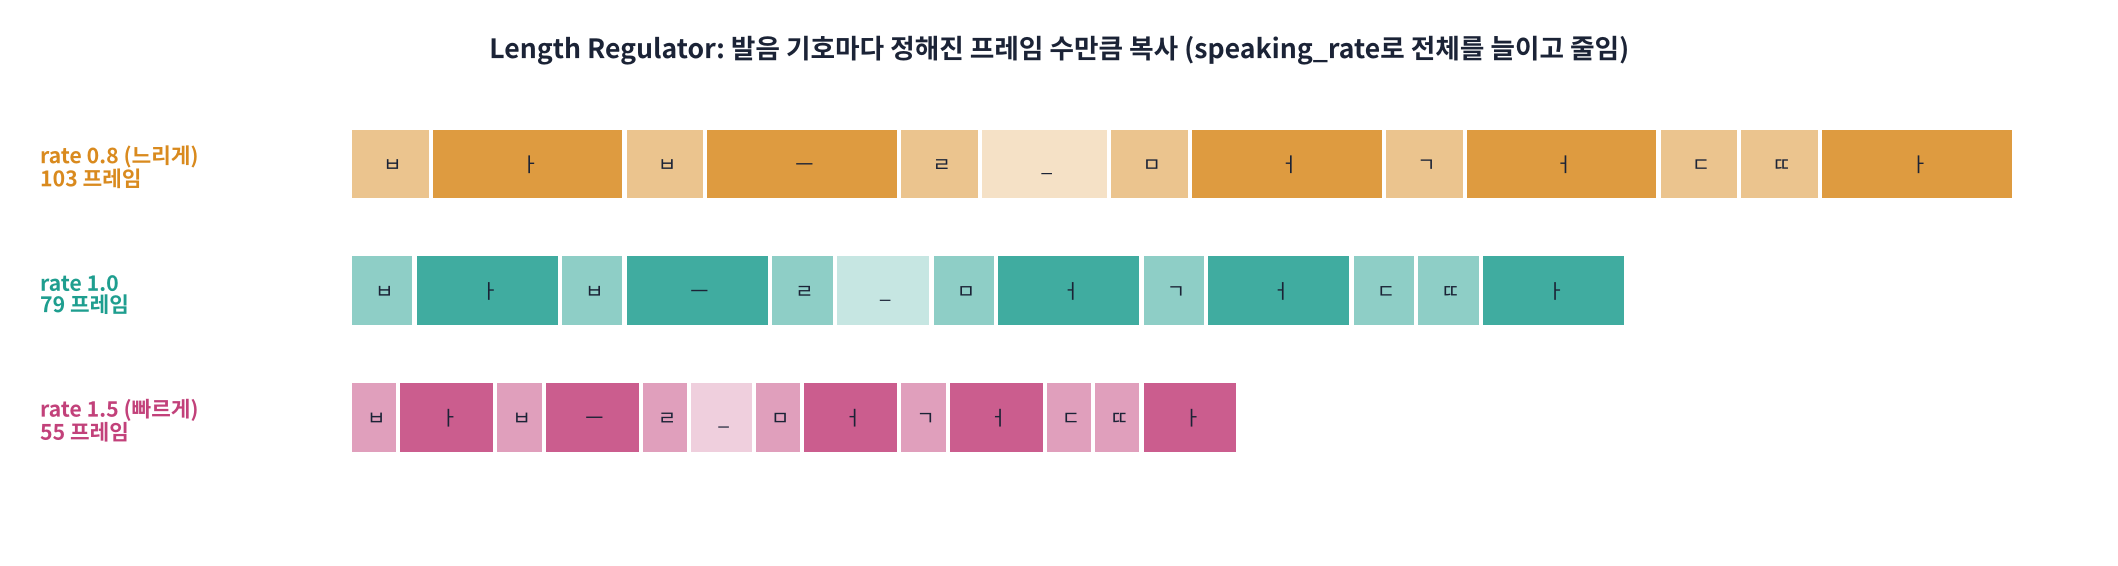

> 🎬 **애니메이션 D16-6:** [길이 조절기](https://imguru-mooc.github.io/AI_Voice/day16/animation.html#duration) — 발음 기호마다 길이를 바꾸고 말 빠르기를 조절해 보기

### 🧩 빈칸 실습 6: Length Regulator
`np.repeat(배열, 횟수, axis=0)`은 각 행을 횟수만큼 반복합니다. 발음 기호별 특징(`enc`)을 **발음 기호별 프레임 수** 배열만큼 반복하세요.

In [ ]:
# 🧩 빈칸 실습 6
def to_jamo(text):                                      # 발음 열 → 자모 열 (소리 없는 초성 ㅇ은 뺌, 띄어쓰기는 '_')
    out = []
    for c in text:
        d = decompose(c)
        if d:
            out += [j for k, j in enumerate(d) if j and not (k == 0 and j == "ㅇ")]
        elif c == " ":
            out.append("_")
    return out

phones = to_jamo(g2p("밥을 먹었다"))
VOWELS = set(JUNG)
durations = np.array([9 if p in VOWELS else (6 if p == "_" else 4) for p in phones])   # 장난감 길이: 모음 9 · 자음 4 · 쉼 6 프레임
enc = np.eye(len(phones))                               # 발음 기호마다 다른 특징 벡터 (설명용: one-hot)

frames = np.repeat(enc, ____, axis=0)                                                    # 빈칸 6
print("발음 열:", " ".join(phones))
print(f"발음 기호 {len(phones)}개 → 프레임 {frames.shape[0]}개 = {frames.shape[0] * HOP / SR:.2f}초")

for rate in [0.8, 1.0, 1.5]:                            # 말 빠르기: duration ÷ rate
    d = np.ceil(durations / rate).astype(int)
    print(f"  speaking_rate {rate}: {d.sum()} 프레임 = {d.sum() * HOP / SR:.2f}초")

fig, ax = plt.subplots(figsize=(11, 2.4))
ax.imshow(frames.T, aspect="auto", cmap="Greens", origin="lower")
ax.set_yticks(range(len(phones))); ax.set_yticklabels(phones, fontsize=7)
ax.set_xlabel("frame"); ax.set_title("length regulator: each phone repeated by its duration")
plt.tight_layout(); plt.show()
check(frames.shape == (durations.sum(), len(phones)) and (frames.argmax(1) == np.repeat(np.arange(len(phones)), durations)).all(),
      hint="빈칸 6 = durations")

> ## 🎤 강사 스크립트 · 빈칸 실습 6  ⏱️ 8분
>
> 🆘 "각 발음 기호를 몇 번 반복? 그 배열 이름" → `durations`
>
> ✅ 예상 출력: 발음 열(ㅂ ㅏ ㅂ ㅡ ㄹ _ ㅁ ㅓ ㄱ ㅓ ㄷ ㄸ ㅏ), `발음 기호 13개 → 프레임 79개 = 1.26초`, rate별 프레임 수, 계단 그림, `✅`.
>
> 🖥️ [D16-6 길이 조절기](https://imguru-mooc.github.io/AI_Voice/day16/animation.html#duration): 모음만 길게, 전체 빠르기.

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
frames = np.repeat(enc, durations, axis=0)
```

**해설**: 결과 행렬의 가로가 시간(프레임)이고, 계단 모양으로 각 발음 기호가 자기 길이만큼 이어집니다. FastSpeech 2는 이 늘어난 행렬을 다시 신경망(디코더)에 넣어 mel을 그립니다. 실제 duration은 사람 녹음에서 정렬 도구(MFA)나 모델이 스스로 찾은 정렬(VITS의 MAS)로 배웁니다. `ceil(duration ÷ rate)`만으로 말이 빨라지고 느려지는 점이 Tacotron 2(어텐션)보다 좋은 점입니다. Part 6에서 VITS의 **진짜 duration**을 꺼내 봅니다.

</details>

**❓ 생각해 보기**: FastSpeech 2는 duration 외에 pitch(음높이)와 energy(세기)도 따로 예측합니다. 왜 그럴까요?

<details>
<summary>답 보기</summary>

같은 발음 · 같은 길이라도 **높낮이 · 세기**에 따라 질문인지 평서문인지, 기쁜지 화났는지가 달라집니다(일대다 문제). 이 정보를 따로 예측하게 하면 ① mel 예측이 쉬워지고(모호함 감소) ② 사용자가 **억양 · 강세를 직접 조절**할 수 있습니다. D18의 감정 · 억양 제어(Chatterbox)도 같은 생각에서 출발합니다.

</details>

## Part 5. Vocoder: 소리 그림을 진짜 소리로

> 💬 **쉽게 말하면**: mel에는 **위상(phase)** 정보가 없습니다(D3). 같은 mel이라도 위상에 따라 소리가 다르므로, Vocoder는 '그럴듯한 위상'을 채워 파형을 만듭니다. 옛 방법 **Griffin-Lim**은 계산을 반복해 위상을 추정하고(로봇 같은 소리), **HiFi-GAN**은 사람 녹음으로 학습한 신경망이 한 번에 파형을 만듭니다(깨끗하고 빠름).

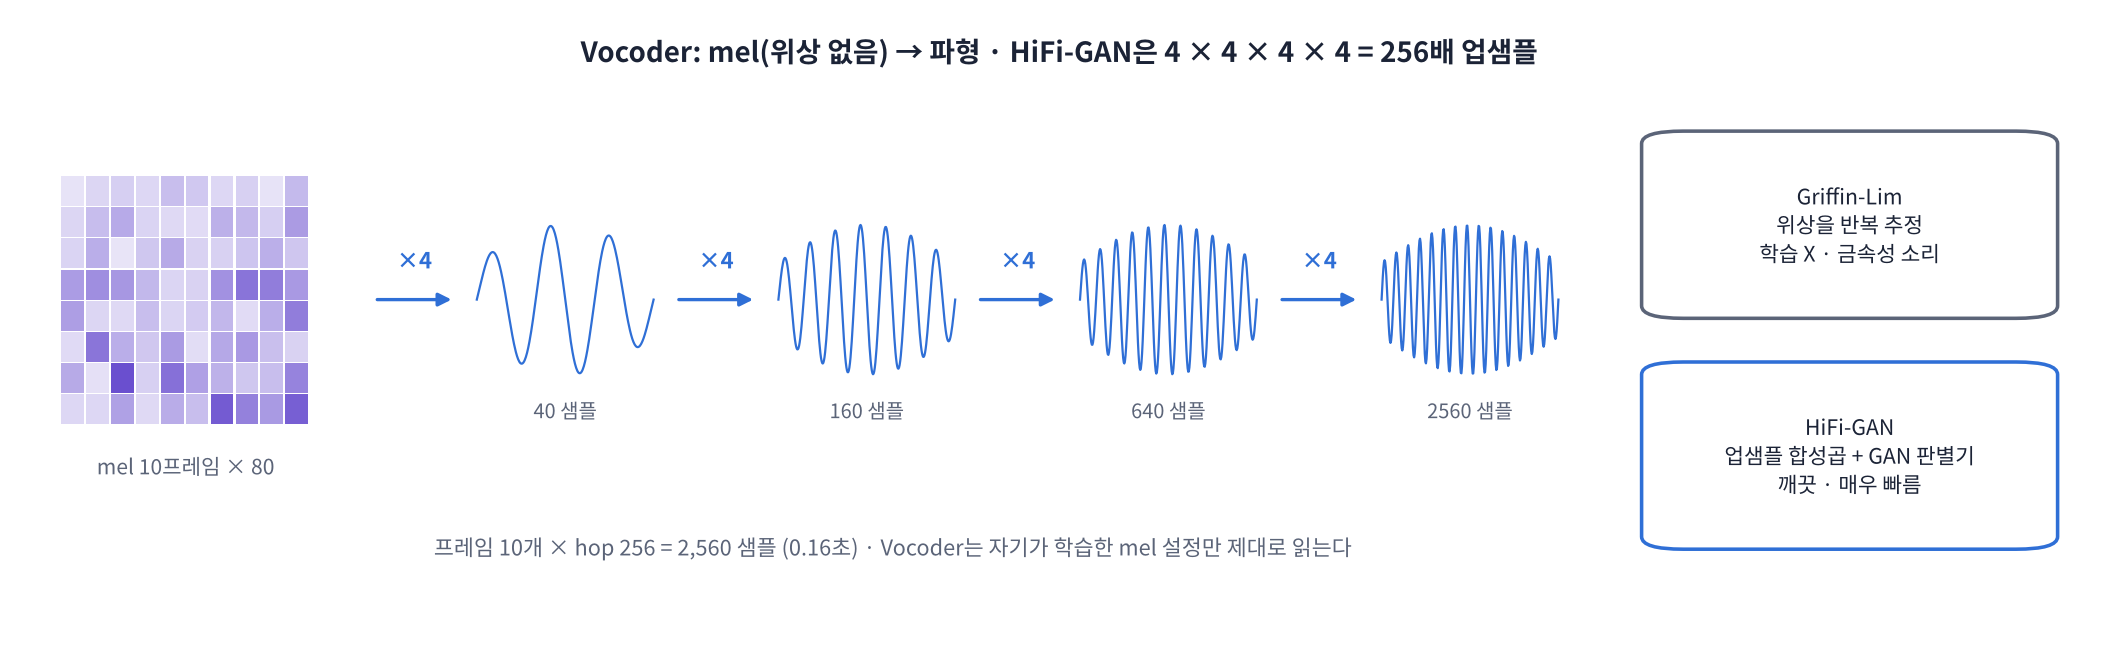

| | Griffin-Lim (2016 ~) | WaveNet (2016) | HiFi-GAN (2020) |
|---|---|---|---|
| 방식 | 반복 계산으로 위상 추정 | 샘플을 하나씩 자기회귀 | **업샘플링 합성곱 + GAN 판별기** |
| 학습 | 필요 없음 | 필요 | 필요 |
| 품질 | 금속성 · 웅웅거림 | 매우 좋음 | 매우 좋음 |
| 속도 | 보통 | 매우 느림 | **실시간보다 수십 ~ 수백 배 빠름** |

> 📐 **핵심 식 하나: 업샘플 배수의 곱 = hop** — mel 한 프레임이 hop개 샘플이 되어야 하므로, HiFi-GAN은 4 × 4 × 4 × 4 = 256배로 늘립니다.

> 🎬 **애니메이션 D16-7:** [Vocoder 비교](https://imguru-mooc.github.io/AI_Voice/day16/animation.html#vocoder) — Griffin-Lim 반복 횟수와 HiFi-GAN 업샘플 단계를 눈으로 보기

> ## 🎤 강사 스크립트 · Part 5 Vocoder  ⏱️ 10분
>
> 🎯 **mel에는 위상이 없다. Vocoder가 그럴듯한 위상을 채운다. 업샘플 곱 = hop.**
>
> 🎧 Griffin-Lim 셀 → 스피커로 원본과 번갈아 들려주기. "로봇 같다, 웅웅거린다"가 나오면 성공.
>
> 🖥️ [D16-7 Vocoder 비교](https://imguru-mooc.github.io/AI_Voice/day16/animation.html#vocoder): Griffin-Lim 반복 횟수를 늘려도 한계가 있는 것.

In [ ]:
t0 = time.time()
y_gl = librosa.feature.inverse.mel_to_audio(M, sr=SR, n_fft=N_FFT, hop_length=HOP, fmin=FMIN, fmax=FMAX, n_iter=32)
T_GL = time.time() - t0
print(f"Griffin-Lim 32회: {T_GL:.2f}초")
play(y_gl, label="Griffin-Lim (위상을 반복 추정)")

### 🧩 빈칸 실습 7: HiFi-GAN의 업샘플 배수
`microsoft/speecht5_hifigan`은 80개 mel(16 kHz, hop 16 ms)을 받아 파형을 만듭니다. 설정(`vocoder.config`)에서 **업샘플 배수 목록**의 이름을 찾아 넣으세요. 배수를 모두 곱하면 hop이 되어야 합니다.

In [ ]:
# 🧩 빈칸 실습 7
from transformers import SpeechT5HifiGan, SpeechT5FeatureExtractor

fe = SpeechT5FeatureExtractor.from_pretrained("microsoft/speecht5_tts")           # HiFi-GAN이 학습한 것과 같은 mel 설정
vocoder = SpeechT5HifiGan.from_pretrained("microsoft/speecht5_hifigan").to(DEVICE).eval()

mel_t5 = fe(audio_target=y_real, sampling_rate=SR, return_tensors="pt")["input_values"][0]   # (프레임, 80) log-mel
hop_v = int(np.prod(vocoder.config.____))                                                 # 빈칸 7
t0 = time.time()
with torch.no_grad():
    y_hifi = vocoder(mel_t5.to(DEVICE)).cpu().numpy()
T_HIFI = time.time() - t0
print(f"mel {tuple(mel_t5.shape)} → 파형 {len(y_hifi):,} 샘플 · 업샘플 {vocoder.config.upsample_rates} → ×{hop_v} · {T_HIFI:.2f}초")
print(f"HiFi-GAN 파라미터 {sum(p.numel() for p in vocoder.parameters()) / 1e6:.1f}M")
play(y_hifi, label="HiFi-GAN (학습한 신경망)")
check(hop_v == 256 and len(y_hifi) == mel_t5.shape[0] * hop_v, hint="빈칸 7 = upsample_rates")

> ## 🎤 강사 스크립트 · 빈칸 실습 7  ⏱️ 10분
>
> 🆘 "config에서 'upsample'로 시작하는 배수 목록" → `upsample_rates`
>
> ✅ 예상 출력: `mel (N, 80) → 파형 N×256 샘플 · 업샘플 (4, 4, 4, 4) → ×256 · 0.1초 안팎`, `HiFi-GAN 파라미터 …M`(VITS 전체보다 작음), `✅`.
>
> 🎧 HiFi-GAN → Griffin-Lim → 원본 순서로 들려주기. 표에서 mel 차이도 HiFi-GAN이 작음. 마지막 '프레임 2배' 소리: 음높이 그대로 느려짐(테이프를 느리게 튼 것과 비교해 설명).
>
> ⚠️ Part 4의 librosa mel을 HiFi-GAN에 넣으면 지글거림 → '같은 mel 설정' 원칙.

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
hop_v = int(np.prod(vocoder.config.upsample_rates))
```

**해설**: 업샘플 배수가 (4, 4, 4, 4)라 프레임 하나가 256 샘플(16 ms)이 됩니다. 프레임 수 × 256 = 파형 길이가 정확히 맞는 것을 확인하세요. 각 업샘플 단계 뒤에는 여러 크기의 합성곱 묶음(MRF)이 있어 다양한 주기의 소리를 만들고, 학습 때는 **판별기(Discriminator)** 가 '진짜 녹음인지'를 가려내며 생성기를 다그칩니다(GAN). 이 mel은 SpeechT5 방식(log10, 80 ~ 7600 Hz)이라 Part 4의 librosa mel과 숫자 범위가 다릅니다. **Vocoder는 자기가 학습한 mel 설정과 똑같은 mel만** 제대로 읽습니다.

</details>

In [ ]:
def mel_dist(y):                                        # 원본과의 log-mel 평균 차이 (작을수록 비슷)
    a = fe(audio_target=y_real, sampling_rate=SR, return_tensors="np")["input_values"][0]
    b = fe(audio_target=np.asarray(y, dtype=np.float32), sampling_rate=SR, return_tensors="np")["input_values"][0]
    n = min(len(a), len(b))
    return float(np.abs(a[:n] - b[:n]).mean())

VOC = pd.DataFrame([dict(방법="Griffin-Lim 32회", 걸린시간_초=T_GL, mel_차이=mel_dist(y_gl)),
                    dict(방법="HiFi-GAN", 걸린시간_초=T_HIFI, mel_차이=mel_dist(y_hifi))]).round(3)
display(VOC)

# 실험: mel 프레임을 두 번씩 반복하면? (길이 조절을 mel에서)
with torch.no_grad():
    y_slow = vocoder(torch.repeat_interleave(mel_t5, 2, dim=0).to(DEVICE)).cpu().numpy()
play(y_slow, label="mel 프레임 2배 반복 → HiFi-GAN (음높이는 그대로, 길이만 2배)")

**결과 읽기 · 들어 보기**
- 🎧 Griffin-Lim은 **금속성 · 웅웅거림**이 들리고, HiFi-GAN은 원본에 가깝습니다. mel 차이 숫자도 대개 HiFi-GAN이 작습니다.
- 🎧 mel 프레임을 반복하면 **음높이는 그대로 · 말만 느려집니다.** 소리를 단순히 느리게 재생하면 음이 낮아지는 것과 다릅니다. TTS가 duration으로 말 빠르기를 조절하는 원리입니다.

**❓ 생각해 보기**: Vocoder만 바꿔도 TTS 품질이 크게 달라진다면, TTS 모델을 평가할 때 무엇을 조심해야 할까요?

<details>
<summary>답 보기</summary>

Acoustic Model을 비교할 때는 **같은 Vocoder**를 써야 공정합니다(D14의 '같은 시험지'). 또 Vocoder 자체의 한계를 알려면 **진짜 녹음의 mel → Vocoder**(오늘 한 copy synthesis)를 먼저 들어 봅니다. 이것이 그 Vocoder로 낼 수 있는 **최고 품질(상한)** 입니다. VITS처럼 Vocoder가 모델 안에 들어 있는 End-to-end 모델은 이런 분리가 없어 통째로 평가합니다.

</details>

---
### 📝 3교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 3교시 탭](https://imguru-mooc.github.io/AI_Voice/day16/worksheet.html)** — mel 프레임 · hop 계산, Tacotron 2 어텐션 vs FastSpeech 2 duration, length regulator, pitch · energy, 위상 문제, Griffin-Lim · WaveNet · HiFi-GAN, 업샘플 곱 = hop, 같은 mel 설정, copy synthesis
>
> 10문항을 풀고 **채점하기**를 누르세요.

> ## 🎤 강사 스크립트 · 3교시 워크시트  ⏱️ 5분
>
> 🖥️ [worksheet.html 3교시 탭](https://imguru-mooc.github.io/AI_Voice/day16/worksheet.html). 자주 틀리는 문항: **업샘플 곱 = hop**, **위상**, **Tacotron 2 vs FastSpeech 2**.

## Part 6. End-to-end: 한국어 VITS (MMS-TTS)

> 💬 **쉽게 말하면**: VITS는 **Acoustic Model과 Vocoder를 한 모델에** 넣고 함께 학습합니다. 텍스트 인코더가 발음 열을 이해하고, **duration predictor**가 길이를 정하고, **flow**가 소리의 특징을 만들고, 맨 끝의 **HiFi-GAN 디코더**가 바로 파형을 냅니다. mel을 중간에 꺼내 넘기지 않아 단계 사이의 어긋남이 없습니다.

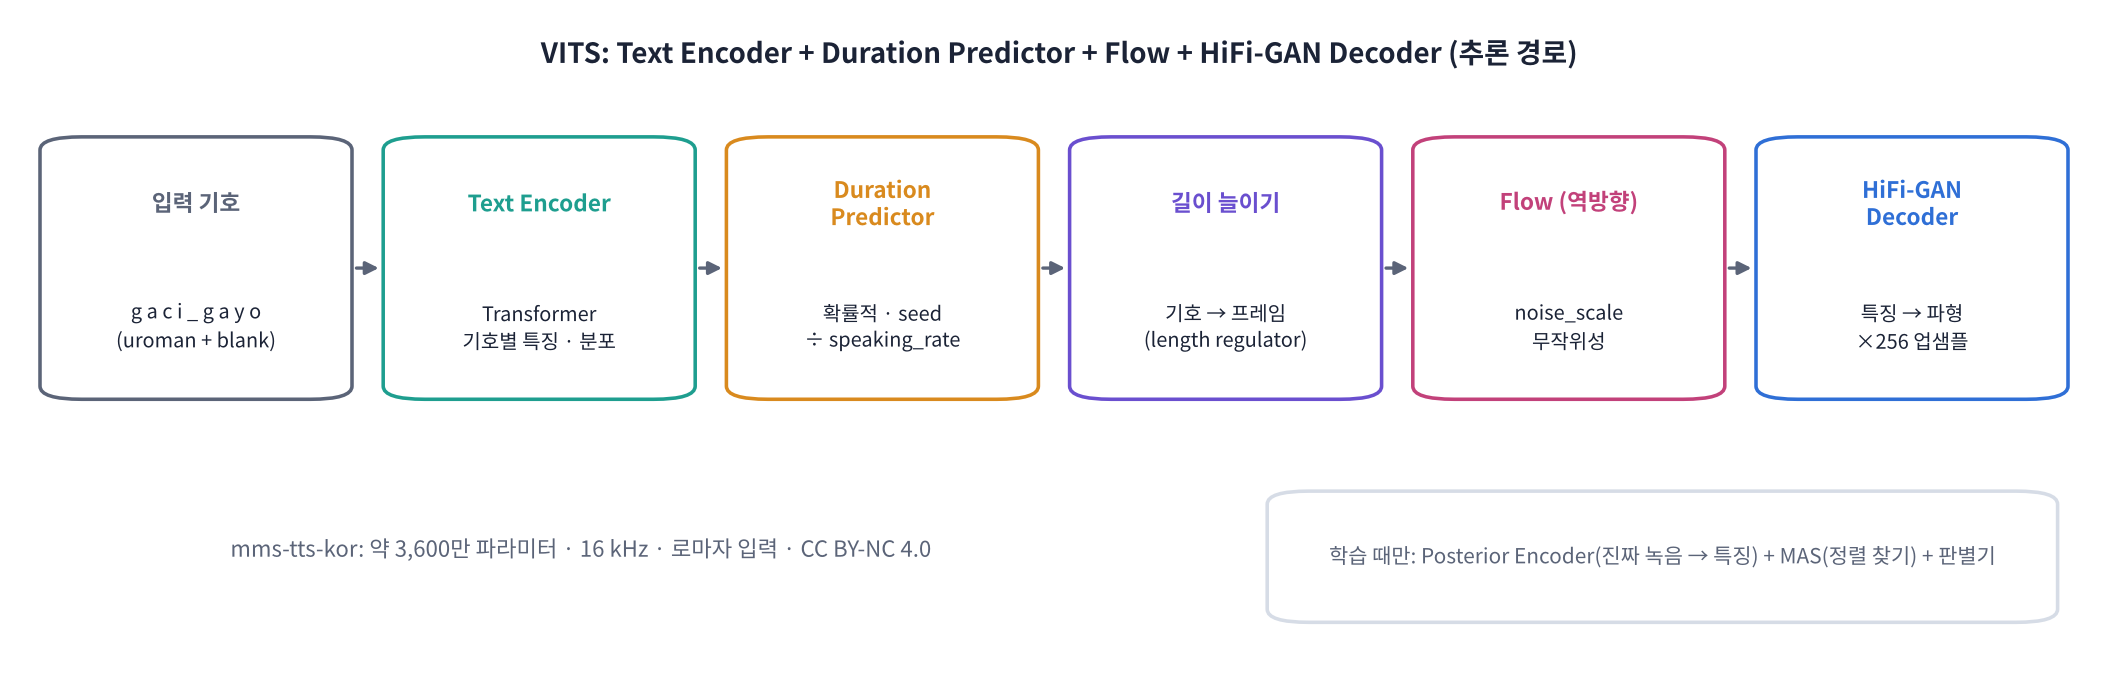

| 부품 | 하는 일 | 오늘 볼 것 |
|---|---|---|
| Text Encoder | 기호 열 → 기호별 특징 | 입력 기호 (로마자 + blank) |
| Duration Predictor (확률적) | 기호마다 프레임 수 | hook으로 꺼내 막대그래프 |
| Flow | 간단한 분포 ↔ 소리 특징 변환 | `noise_scale` (무작위성) |
| HiFi-GAN Decoder | 특징 → 파형 | Part 5와 같은 구조 |
| Posterior Encoder (학습 때만) | 진짜 녹음 → 특징 | 추론 때는 안 씀 |

`facebook/mms-tts-kor`는 Meta의 MMS 프로젝트가 1,100여 언어로 만든 VITS 중 한국어 모델(약 3,600만 파라미터)입니다. 입력은 한글이 아니라 **로마자**라서, **uroman**으로 한글을 로마자로 바꿔 넣어야 합니다.

> 🎬 **애니메이션 D16-8:** [VITS 해부](https://imguru-mooc.github.io/AI_Voice/day16/animation.html#vits) — 부품을 눌러 입력 · 출력과 조절 손잡이 보기

> ## 🎤 강사 스크립트 · Part 6 VITS  ⏱️ 8분
>
> 🎯 **VITS 안에서 오늘 배운 부품(duration · length regulator · HiFi-GAN)을 다시 찾는다.**
>
> 🖥️ [D16-8 VITS 해부](https://imguru-mooc.github.io/AI_Voice/day16/animation.html#vits): 부품마다 클릭.
>
> ✅ 모델 셀 출력: `샘플링 16000 Hz · hop 256 · 파라미터 약 36M`, `uroman 필요? True · 디코더: VitsHifiGan`, 기호 목록(로마자 소문자 등).
>
> ⚠️ 라이선스: **CC BY-NC 4.0** — 다시 한 번 짚기.

In [ ]:
from transformers import VitsModel, AutoTokenizer, set_seed

tts_tok = AutoTokenizer.from_pretrained("facebook/mms-tts-kor")
tts = VitsModel.from_pretrained("facebook/mms-tts-kor").to(DEVICE).eval()
TTS_SR = tts.config.sampling_rate
HOP_V = int(np.prod(tts.config.upsample_rates))
VOCAB = set(tts_tok.get_vocab())
print(f"샘플링 {TTS_SR} Hz · hop {HOP_V} · 파라미터 {sum(p.numel() for p in tts.parameters()) / 1e6:.1f}M · 기호 {len(VOCAB)}개")
print("uroman 필요?", tts_tok.is_uroman, "· 디코더:", type(tts.decoder).__name__, "· 기본 noise_scale", tts.noise_scale, "· speaking_rate", tts.speaking_rate)
print("기호 목록:", "".join(sorted(VOCAB)))

### 🧩 빈칸 실습 8: 한글 → 로마자 (uroman)
`uroman.Uroman()` 객체에서 **문자열 하나를 로마자로 바꾸는 메서드**를 부르세요. 세 가지 입력 방식을 비교합니다.
- **A 원문**: 원문 → uroman
- **B G2P**: 원문 → g2pk2 → uroman
- **C 정규화 + G2P**: 원문 → normalize_ko → g2pk2 → uroman

In [ ]:
# 🧩 빈칸 실습 8
import uroman as ur
U = ur.Uroman()

def romanize(text):
    return U.____(text)                                                                  # 빈칸 8

MODES = {"A 원문": lambda s: s, "B G2P": lambda s: g2p(s), "C 정규화+G2P": lambda s: g2p(normalize_ko(s))}

def prep(text, mode):
    r = romanize(MODES[mode](text))
    dropped = sorted(set(r.lower()) - VOCAB)            # 모델이 모르는 기호 → 토크나이저가 지움
    return r, dropped

for s in ["같이 밥을 먹으러 갈까요", "회의는 오후 3시 15분에 시작합니다", "할인율은 25%입니다"]:
    for mode in MODES:
        r, dropped = prep(s, mode)
        print(f"{mode:10s} {r:45s} 지워지는 기호: {' '.join(dropped) or '없음'}")
    print()
ids = tts_tok(prep("같이 밥을", "B G2P")[0]).input_ids
print("토큰 (blank 포함):", tts_tok.convert_ids_to_tokens(ids))
check(romanize("이봐 무슨 일이야").startswith("ibwa") and romanize("같이") == "gati", hint="빈칸 8 = romanize_string")

> ## 🎤 강사 스크립트 · 빈칸 실습 8  ⏱️ 8분
>
> 🆘 "'문자열(string)을 로마자로(romanize)'라는 메서드 이름" → `romanize_string`
>
> ✅ 예상 출력: 세 문장 × 세 방식 로마자. 예: 'gati babeul meogeureo' vs 'gaci babeul meogeureo'. 원문 방식의 '3시' 줄에서 '지워지는 기호'에 숫자 · % 표시(기호 목록에 숫자가 없을 때). 토큰 목록에 blank가 번갈아 들어감.
>
> ❓ "왜 원문 로마자에는 숫자가 그대로 남나요?" → uroman은 글자를 옮길 뿐, 숫자를 읽지 않음.

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
return U.romanize_string(text)
```

**해설**: uroman은 **글자를 하나씩** 로마자로 옮깁니다(같이 → gati). 발음 규칙은 모르므로 G2P를 먼저 하면 소리에 가까운 로마자가 됩니다(가치 → gaci). 원문의 '3'이나 '%'는 로마자로 바뀌지 않고 그대로 남습니다. 위에서 출력한 **기호 목록에 없는 문자는 토크나이저가 조용히 지우므로**, '지워지는 기호' 칸에 숫자가 보이면 '오후 시 분에'처럼 숫자가 빠진 소리가 나옵니다. 참고: 최신 transformers의 VITS 토크나이저는 uroman이 설치돼 있으면 한글을 **자동으로** 로마자로 바꾸기도 합니다. 오늘은 과정을 눈으로 보려고 직접 바꿨습니다. 토큰 사이사이의 `blank`(0번)는 VITS가 기호 사이 전환을 표현하려고 넣는 빈 기호입니다(add_blank).

</details>

### 🧩 빈칸 실습 9: VITS의 duration 꺼내 보기
`register_forward_hook`으로 duration predictor의 출력(**로그 duration**)을 가로챕니다. VITS는 `프레임 수 = ceil(exp(로그 duration) ÷ speaking_rate)`로 길이를 정합니다. 로그를 되돌리는 `torch.exp()` 안에 가로챈 값을 넣으세요.

In [ ]:
# 🧩 빈칸 실습 9
CAP = {}
hook = tts.duration_predictor.register_forward_hook(lambda mod, inp, out: CAP.__setitem__("log_dur", out.detach().cpu()))

def synth(roman, speaking_rate=1.0, seed=0):
    inputs = tts_tok(roman, return_tensors="pt").to(DEVICE)
    set_seed(seed)                                      # flow · duration에 무작위성이 있어 seed 고정
    with torch.no_grad():
        out = tts(**inputs, speaking_rate=speaking_rate)
    return out.waveform[0].cpu().numpy(), inputs["input_ids"][0].cpu()

roman, _ = prep("같이 밥을 먹으러 갈까요", "C 정규화+G2P")
wav, ids = synth(roman)
dur = torch.ceil(torch.exp(____) / 1.0)[0, 0]                                             # 빈칸 9
print(f"기호 {len(ids)}개 · 프레임 합 {int(dur.sum())} × hop {HOP_V} = {int(dur.sum()) * HOP_V:,} 샘플 · 실제 파형 {len(wav):,} 샘플")
play(wav, TTS_SR, label=f"VITS · {roman}")

toks = [t if i % 2 else "·" for i, t in enumerate(tts_tok.convert_ids_to_tokens(ids))]   # 짝수 자리 = blank
fig, ax = plt.subplots(figsize=(11, 2.6))
ax.bar(range(len(dur)), dur.numpy(), color=["#C9CED8" if t == "·" else "#1E9E8F" for t in toks])
ax.set_xticks(range(len(dur))); ax.set_xticklabels(toks, fontsize=8)
ax.set_ylabel("frames"); ax.set_title("VITS predicted duration per input symbol (gray = blank)")
plt.tight_layout(); plt.show()
check(int(dur.sum()) * HOP_V == len(wav), hint="빈칸 9 = CAP[\"log_dur\"]")

> ## 🎤 강사 스크립트 · 빈칸 실습 9  ⏱️ 10분
>
> 🆘 "hook이 가로챈 값을 담아 둔 사전과 키" → `CAP["log_dur"]`
>
> ✅ 예상 출력: `기호 N개 · 프레임 합 F × hop 256 = … 샘플 · 실제 파형 … 샘플`(두 숫자 같음), 🎧 소리, 막대그래프(모음 길고 blank 짧음), `✅`.
>
> 🎧 다음 셀: speaking_rate 0.8 / 1.0 / 1.3, noise_scale 0 / 0.667 / 1.0 — 스피커로. noise 0은 '로봇처럼 평평', 1.0은 '들쭉날쭉'.

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
dur = torch.ceil(torch.exp(CAP["log_dur"]) / 1.0)[0, 0]
```

**해설**: duration 합 × hop이 파형 길이와 **정확히 같습니다.** VITS 안에서도 Part 4의 length regulator와 같은 일이 일어난다는 증거입니다. 막대그래프에서 모음 기호가 길고 자음 · blank가 짧은지 보세요. VITS의 duration predictor는 **확률적(stochastic)** 이라 seed가 바뀌면 길이도 조금씩 바뀝니다(`noise_scale_duration`). 같은 문장도 매번 조금 다르게 말하는 것, 이것이 일대다 문제에 대한 VITS의 답입니다.

</details>

In [ ]:
# 🎧 조절 손잡이: 말 빠르기 · 무작위성
s = prep("국물이 정말 맛있네요", "C 정규화+G2P")[0]
for rate in [0.8, 1.0, 1.3]:
    w, _ = synth(s, speaking_rate=rate)
    play(w, TTS_SR, label=f"speaking_rate = {rate}")

default_noise = tts.noise_scale
for ns in [0.0, default_noise, 1.0]:
    tts.noise_scale = ns
    w, _ = synth(s)
    play(w, TTS_SR, label=f"noise_scale = {ns}")
tts.noise_scale = default_noise

**들어 보기**
- `speaking_rate`가 클수록 빨라지고 파형이 짧아집니다(duration ÷ rate).
- `noise_scale = 0`이면 무작위성이 없어 **단조롭고 평평한** 소리, 1.0이면 **변화가 크지만 불안정**한 소리가 됩니다. 기본값(0.667)은 그 사이에서 고른 값입니다.

**❓ 생각해 보기**: 한국어 VITS가 로마자를 입력으로 쓰는 것의 장점과 단점은 무엇일까요?

<details>
<summary>답 보기</summary>

장점: 1,100여 언어를 **같은 방식(uroman)** 으로 다룰 수 있어 언어를 늘리기 쉽습니다. 단점: 한글 → 로마자 변환에서 정보가 사라집니다. 예를 들어 'ㅓ'와 'ㅗ'가 eo · o로 구분되긴 하지만, 받침 · 경음 표기가 모호해지고 숫자 · 기호는 아예 빠집니다. 그래서 **한국어 전용 모델**(자모 · 음소 입력)이 보통 더 자연스럽고, 다국어 모델을 쓸 때는 **정규화 · G2P를 앞에 붙이는 것**이 특히 중요합니다(Part 7). 다음 시간 Kokoro(D17)는 음소(IPA) 입력을 씁니다.

</details>

## Part 7. 정규화 · G2P는 얼마나 도움이 될까: ASR 역검증

> 💬 **쉽게 말하면**: TTS가 **알아듣게 말했는지**를 사람 대신 **Whisper에게 받아쓰게** 해서 잽니다. 받아쓴 결과가 원문과 가까울수록(CER ↓) 또박또박 말한 것입니다. 세 가지 입력 방식(A 원문 · B G2P · C 정규화 + G2P)으로 같은 문장 12개를 합성해 비교합니다.

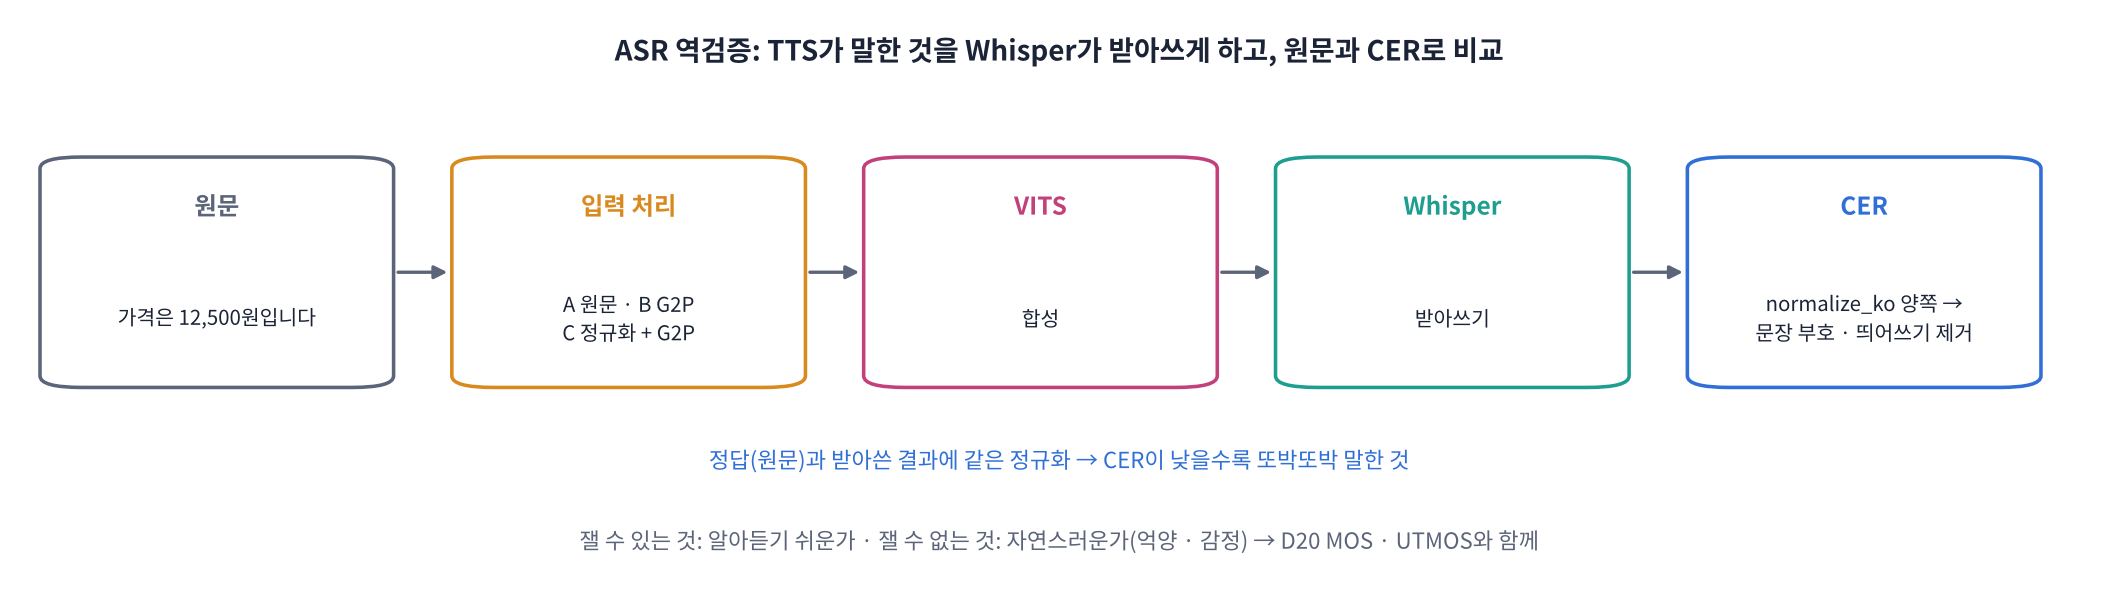

> ⚠️ **같은 채점 기준**(D10 · D14): Whisper는 '3시'처럼 숫자로 받아쓰기도 하므로, 원문과 받아쓴 결과 **모두에 같은 `normalize_ko()`** 를 적용한 뒤 문장 부호 · 띄어쓰기를 지우고 CER을 잽니다.

> 🎬 **애니메이션 D16-9:** [ASR 역검증](https://imguru-mooc.github.io/AI_Voice/day16/animation.html#backcheck) — 정답 · 받아쓴 결과와 정규화 여부를 바꾸며 CER 계산

> ## 🎤 강사 스크립트 · Part 7 ASR 역검증  ⏱️ 15분
>
> 🎯 **앞 처리(정규화 · G2P)가 알아듣기 쉬움을 크게 바꾼다 — 숫자로 확인.**
>
> 🖥️ [D16-9 ASR 역검증](https://imguru-mooc.github.io/AI_Voice/day16/animation.html#backcheck): 정규화를 끄면 같은 말도 CER이 커지는 것.
>
> ✅ 예상(T4, whisper-small): 평균 CER은 보통 **A > B > C** 순. 숫자 · 기호 문장에서 A가 특히 높음. 실행 시간 3 ~ 5분.
>
> 🎧 '가격은 12,500원입니다' 세 방식을 스피커로 → A는 숫자를 건너뜀.
>
> ❓ "C가 B보다 나쁜 문장이 있다면?" → 정규화가 틀렸거나(규칙 밖 표현) Whisper 오류. 문장별 표에서 찾아 들어 보게 하기.

In [ ]:
from transformers import WhisperProcessor, WhisperForConditionalGeneration

ASR_NAME = "openai/whisper-small" if GPU else "openai/whisper-tiny"
asr_proc = WhisperProcessor.from_pretrained(ASR_NAME, language="korean", task="transcribe")
asr = WhisperForConditionalGeneration.from_pretrained(ASR_NAME).to(DEVICE).eval()

def transcribe(wavs, sr):
    xs = [librosa.resample(w, orig_sr=sr, target_sr=SR) if sr != SR else w for w in wavs]
    feats = asr_proc.feature_extractor(xs, sampling_rate=SR, return_tensors="pt").input_features.to(DEVICE)
    with torch.no_grad():
        ids = asr.generate(input_features=feats, language="korean", task="transcribe", max_new_tokens=128)
    return [t.strip() for t in asr_proc.batch_decode(ids, skip_special_tokens=True)]

def for_cer(s):                                         # 양쪽에 같은 기준: 정규화 → 문장 부호 · 띄어쓰기 제거
    return re.sub(r"[^\w]", "", normalize_ko(s))

rows, WAVS = [], {}
t0 = time.time()
for mode in MODES:
    wavs = [synth(prep(s, mode)[0])[0] for s in TEST_SENTS]
    WAVS[mode] = wavs
    hyps = transcribe(wavs, TTS_SR)
    for s, h, w in zip(TEST_SENTS, hyps, wavs):
        rows.append(dict(방식=mode, 원문=s, 받아쓰기=h, 초=round(len(w) / TTS_SR, 2),
                         CER=100 * jiwer.cer(for_cer(s), for_cer(h) or "∅")))
BACK = pd.DataFrame(rows)
print(f"{len(BACK)}개 합성 + 받아쓰기 · {time.time() - t0:.0f}초 · ASR {ASR_NAME}")
SUMMARY = BACK.groupby("방식")["CER"].mean().round(1)
display(SUMMARY.to_frame("평균 CER(%)"))
display(BACK.pivot(index="원문", columns="방식", values="CER").round(1))

In [ ]:
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.bar(SUMMARY.index, SUMMARY.values, color=["#9AA4B5", "#D98A1E", "#1E9E8F"])
for i, v in enumerate(SUMMARY.values):
    ax.text(i, v, f"{v:.1f}", ha="center", va="bottom")
ax.set_ylabel("ASR back-check CER (%)  lower = clearer"); ax.set_title("TTS input processing vs intelligibility")
plt.tight_layout(); plt.show()

i = TEST_SENTS.index("가격은 12,500원입니다")                # 숫자가 든 문장 하나를 세 방식으로 들어 보기
for mode in MODES:
    r = BACK[(BACK.방식 == mode) & (BACK.원문 == TEST_SENTS[i])].iloc[0]
    play(WAVS[mode][i], TTS_SR, label=f"{mode} → Whisper: {r.받아쓰기}  (CER {r.CER:.0f}%)")

**결과 읽기** (숫자는 실행마다 조금 다릅니다)
- **A 원문**은 숫자 · 기호가 든 문장에서 CER이 크게 나쁩니다. 숫자 · 기호가 **지워지거나 엉뚱하게 읽혔기** 때문입니다(Part 6의 '지워지는 기호').
- **B G2P**는 연음 · 경음화가 반영돼 일반 문장도 좋아지고, g2pk2가 숫자 일부를 읽어 줍니다.
- **C 정규화 + G2P**가 보통 가장 낮습니다. 특히 %, 원, 전화번호, km, 영문 약어 문장에서 차이가 큽니다.

> ⚠️ **ASR 역검증의 한계**: ① Whisper 자체의 오류가 섞이고 ② **알아듣기 쉬운가**만 재지 **자연스러운가(억양 · 감정)** 는 재지 못합니다. 그래서 D20에서 사람 평가(MOS) · 자동 MOS(UTMOS)와 함께 씁니다. 문장 12개는 적으니 D14의 부트스트랩으로 차이가 확실한지도 확인할 수 있습니다(과제).

**❓ 생각해 보기**: D15에서 만든 도메인 LoRA 받아쓰기 모델로 역검증하면 어떤 점이 좋고, 어떤 점을 조심해야 할까요?

<details>
<summary>답 보기</summary>

좋은 점: 의료 용어 같은 **도메인 문장**을 TTS가 제대로 말했는지 더 정확히 잴 수 있습니다(원래 Whisper는 용어를 몰라서 TTS 탓인지 ASR 탓인지 헷갈림). 조심할 점: 그 LoRA는 **gTTS 합성음으로 학습**해서 합성음에 유리할 수 있습니다. 즉 사람이 듣기엔 어색해도 높은 점수가 나올 수 있습니다. 역검증 모델과 평가 대상이 **같은 계열 데이터**로 만들어지지 않았는지 늘 확인합니다(D14 누수와 같은 생각).

</details>

---
### 📝 4교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 4교시 탭](https://imguru-mooc.github.io/AI_Voice/day16/worksheet.html)** — VITS 부품, End-to-end의 장점, uroman과 blank, 지워지는 기호, 확률적 duration · seed, speaking_rate · noise_scale, ASR 역검증 방법과 한계, 같은 정규화로 채점, 라이선스
>
> 10문항을 풀고 **채점하기**를 누르세요.

> ## 🎤 강사 스크립트 · 4교시 워크시트 · 제출  ⏱️ 5분
>
> 🖥️ [worksheet.html 4교시 탭](https://imguru-mooc.github.io/AI_Voice/day16/worksheet.html) → 채점 → 제출 → 📋 캡처 → 노션. **Part 7 평균 CER 표**도 함께.
>
> 자주 틀리는 문항: **ASR 역검증으로 잴 수 없는 것**, **blank 토큰**.

## Part 8. 정리 & 과제

### 오늘 배운 것
| 개념 | 한 줄 정리 | 코드 |
|---|---|---|
| TTS 파이프라인 | 정규화 → G2P → Acoustic Model(mel) → Vocoder(파형) | — |
| 텍스트 정규화 | 숫자 · 단위 · 기호를 읽는 말로 (한자어 · 고유어 수) | `sino()`, `native()`, `normalize_ko()` |
| 한글 자모 | 0xAC00 + (초성 × 21 + 중성) × 28 + 종성 | `code // 588` |
| G2P | 연음 · 경음화 · 비음화 · 구개음화 … | `linking()`, `G2p()` |
| mel · 프레임 | 프레임 ≈ 샘플 ÷ hop (16 kHz · 256 → 62.5/초) | `librosa.feature.melspectrogram` |
| Duration | 기호마다 프레임 수 → 복사해 늘이기 | `np.repeat(enc, durations, axis=0)` |
| Vocoder | mel → 파형, 업샘플 곱 = hop | `SpeechT5HifiGan`, `upsample_rates` |
| VITS | 인코더 + duration + flow + HiFi-GAN 한 몸 | `VitsModel`, `speaking_rate`, `noise_scale` |
| ASR 역검증 | 합성음을 받아써서 CER로 '알아듣기 쉬움' 재기 | `jiwer.cer(for_cer(ref), for_cer(hyp))` |

### 📝 과제
1. **정규화기 늘리기**: '3~5개', '1/2', '2:1', '제3장', 'iPhone 17'을 바르게 읽도록 `normalize_ko()`를 고치고, 바꾸기 전후를 표로 제출하세요.
2. **통계로 확인**: Part 7의 A vs C 문장별 CER 차이에 D14의 `bootstrap_diff()`를 적용해, 12문장으로 '개선'을 말할 수 있는지 판정하세요.
3. **내 목소리 vs 합성음**: D15의 내 목소리 문장 10개를 VITS로 합성해 같은 Whisper로 역검증하고, 사람 녹음 CER과 비교하세요.

### ✅ 개념 워크시트 제출
4교시 탭까지 모두 채점했다면 오늘 내용을 정리해 제출합니다.

> 📝 **[D16 개념 워크시트 열기](https://imguru-mooc.github.io/AI_Voice/day16/worksheet.html)** — 4교시 × 10문항 (객관식 5 · OX 2 · 선잇기 1 · 순서 맞추기 1 · 모두 고르기 1)

**제출 방법 (노션)**
1. 4개 교시 탭을 모두 채점합니다.
2. **제출** 버튼을 눌러 오답 정리를 엽니다.
3. **📋 캡처 (노션용 복사)**를 누른 뒤, 노션 제출 페이지에서 `Ctrl + V`로 붙여 넣습니다. **Part 7 평균 CER 표**도 함께 붙이세요.

> 🎬 복습용: [애니메이션 전체 보기](https://imguru-mooc.github.io/AI_Voice/day16/animation.html) — D16-1 ~ D16-9

### 다음 시간 (D17 · 경량 TTS: Kokoro)
**Kokoro**: 8,200만 파라미터의 가벼운 TTS로 CPU에서도 실시간 합성. 설치와 추론, 음성 스타일(voice) 선택, 오늘 배운 G2P(음소 입력) · duration · Vocoder가 Kokoro 안에서 어떻게 쓰이는지 확인합니다.

> ## 🎤 강사 스크립트 · Part 8 정리  ⏱️ 3분
>
> 🎯 **오늘 한 줄: TTS 품질의 절반은 모델 앞(정규화 · G2P)에서, 나머지 절반은 길이와 Vocoder에서.**
>
> ➡️ "다음 시간 Kokoro는 8,200만 파라미터로 CPU에서 실시간입니다. 오늘 본 G2P(음소 입력) · duration · Vocoder가 Kokoro 안에서 어떻게 쓰이는지 찾아봅니다."